# `line_plot`: how a measure moves over time

The chart for trends, seasons and breaks: one line per series over an ordered axis,
usually time, straight from a query in whatever shape it comes. This notebook walks
through every option on Fernway's data, then uses the chart to find out what the April
2025 price rise did to the business.

Every table of the showcase data becomes a SQL view, so each chart below starts from
a query, the way it would in a data warehouse.

In [1]:
from pathlib import Path

import duckdb

import easy_viz as ev

db = duckdb.connect()
for csv in sorted(Path("../data").glob("*.csv")):
    db.sql(f"CREATE VIEW {csv.stem} AS FROM '{csv.as_posix()}'")

## The question

How do Fernway's orders move through the year, and what changed when every price rose
12 % on 1 April 2025? The main story is *Seasonality and a structural break after a
price rise* (pattern 4). Along the way the charts show *Long-tail product categories*
(pattern 5) as weeks without a single Gifts order, *Hidden bimodality: two warehouses*
(pattern 3) as two delivery lines, and *Profit concentration* (pattern 2) on a log
axis.

The first query returns one row per day, as a daily metrics table does.

In [2]:
daily = db.sql("""
    SELECT date, sessions, orders, revenue, conversion_rate, avg_order_value
    FROM daily_metrics
    ORDER BY date
""").pl()

## Bare call

The table and two column names give a finished chart: a calendar read from the dates
(the subtitle says *daily*), every day from the first to the last on the axis, and a
title built from the columns. Two years of daily orders are a noisy zigzag; the
insight story below turns it into a finding.

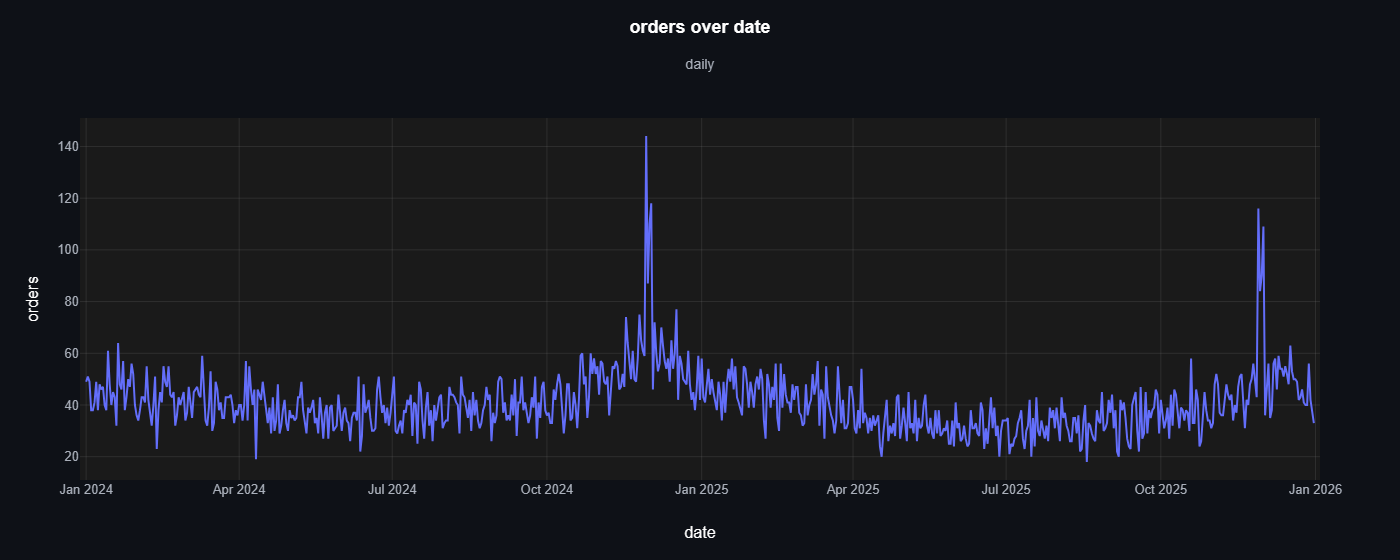

In [3]:
ev.line_plot(daily, "date", "orders")

## Parameter tour

Every option, one change per chart. Defaults and accepted values are quoted from the
docstring (`help(ev.line_plot)`).

### Data and aggregation

**`y` as a list**: a wide table, with several measures side by side in columns, gives
one line per column, named after it. The query returns one row per month, with its
revenue and profit.

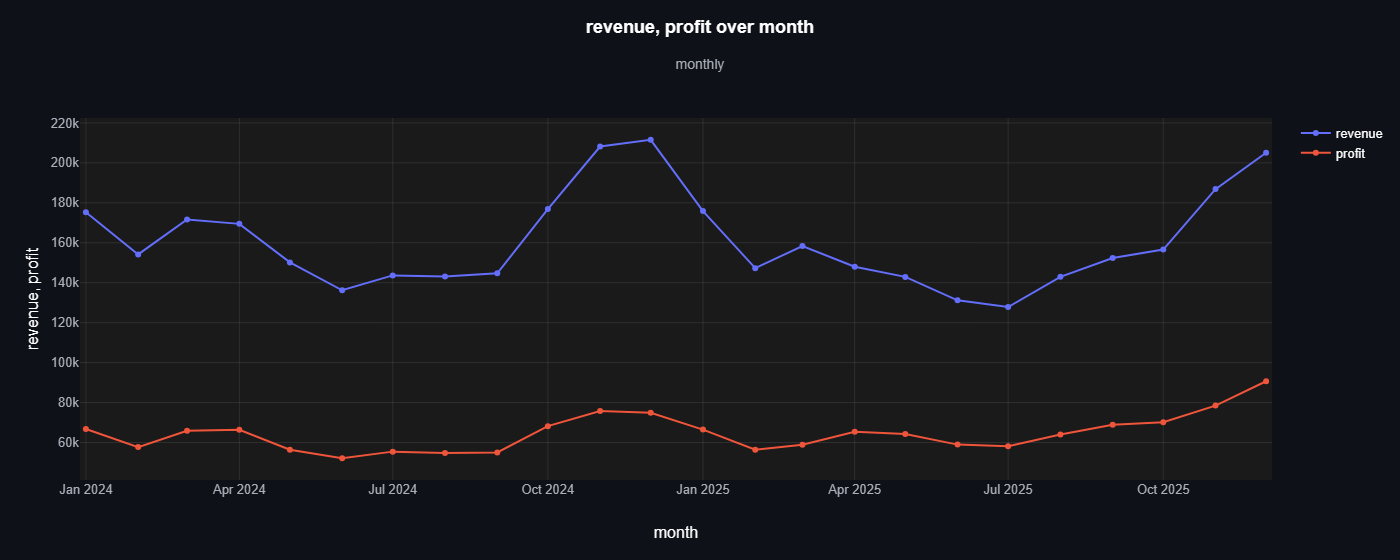

In [4]:
monthly = db.sql("""
    SELECT date_trunc('month', order_date) AS month,
           SUM(revenue) AS revenue,
           SUM(profit)  AS profit,
           COUNT(*)     AS orders
    FROM orders
    GROUP BY month
    ORDER BY month
""").pl()

ev.line_plot(monthly, "month", ["revenue", "profit"])

**`color`** (`str or None, default None`): the column that splits the rows into one
line per value (long format). Monthly revenue per customer region, stacked in one
column as a `GROUP BY month, region` returns it.

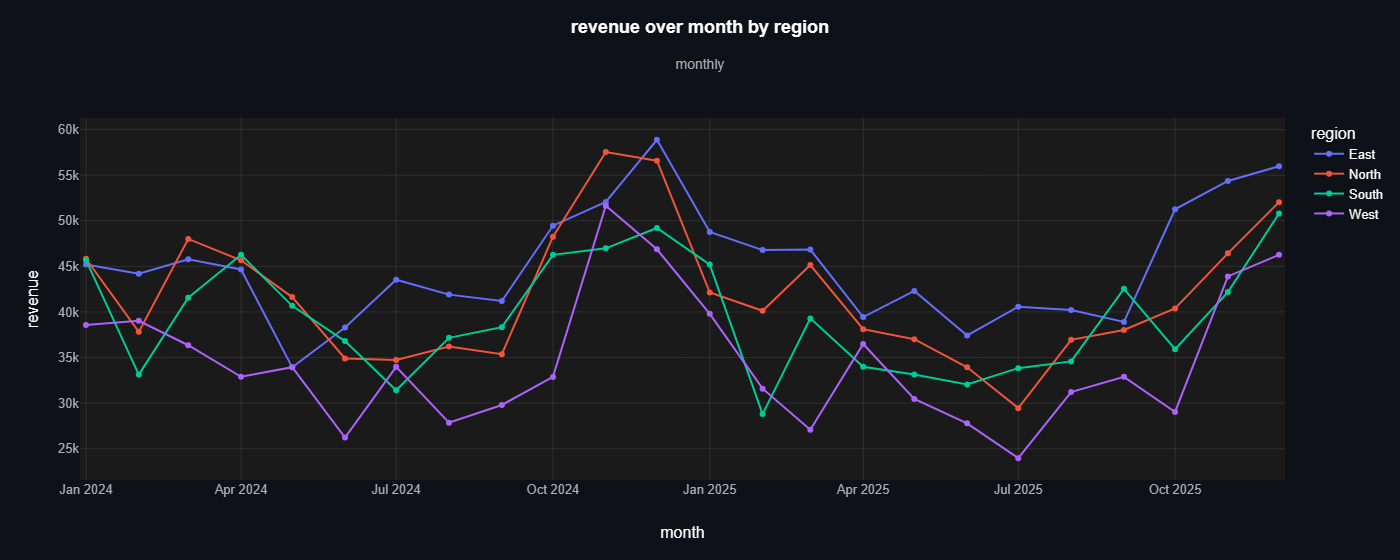

In [5]:
by_region = db.sql("""
    SELECT date_trunc('month', order_date) AS month, region, SUM(revenue) AS revenue
    FROM orders JOIN customers USING (customer_id)
    GROUP BY month, region
    ORDER BY month, region
""").pl()

ev.line_plot(by_region, "month", "revenue", color="region")

**`hover`** (`str, list of str or None, default None`): extra columns shown on hover.
Only with `agg=None`: a combined point has no single value for them. Hover over a
month in Jupyter to see its order count; the static image can't show it.

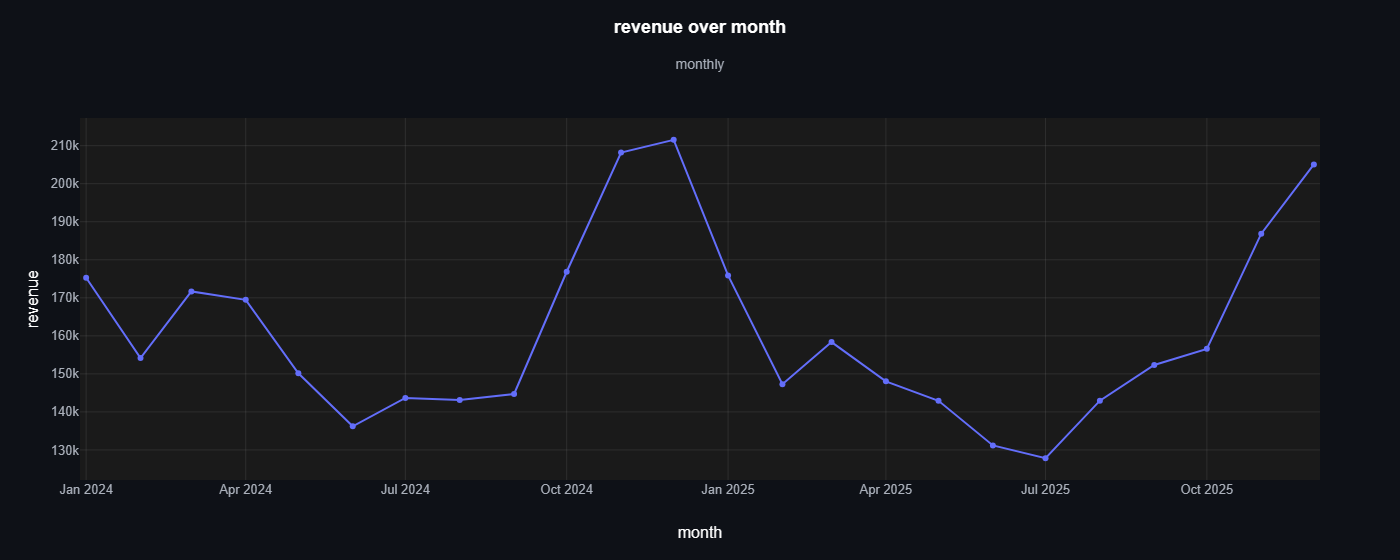

In [6]:
ev.line_plot(monthly, "month", "revenue", hover="orders")

**`agg`** (`{"sum", "mean", "median", "min", "max", "count"} or None, default
None`): `None` plots each row as-is. Raw rows, one per order here, need it:
`agg="sum"` adds up the revenue of each day's orders. The order dates are days, so the
calendar is daily.

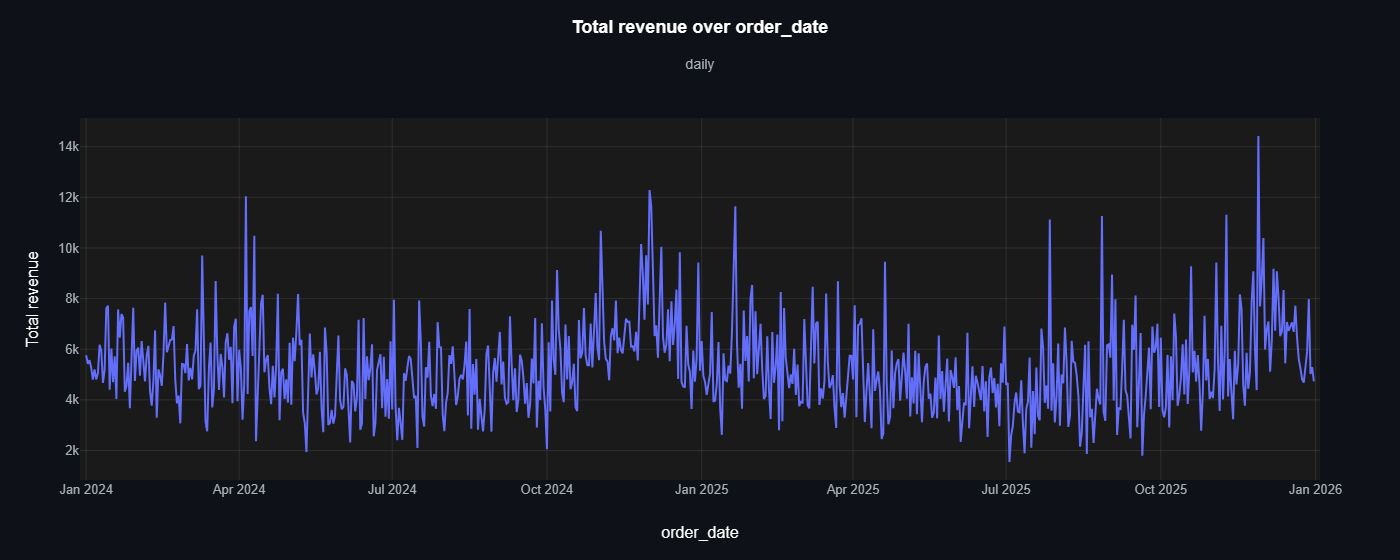

In [7]:
orders = db.sql("""
    SELECT order_date, category, region, warehouse, revenue, profit, delivery_days
    FROM orders
        JOIN products USING (product_id)
        JOIN customers USING (customer_id)
    ORDER BY order_id
""").df()

ev.line_plot(orders, "order_date", "revenue", agg="sum")

**`time_grain`** (`{"hour", "day", "week", "month", "quarter", "year"}, "auto" or
None, default "auto"`): the calendar of a time `x`. Dates are bucketed into this
period (weeks start on Monday, as SQL's `date_trunc('week', ...)`), and every period
from the first to the last is on the axis. The same raw orders, bucketed into months,
give exactly the revenue line of the `monthly` query, which summed per month in SQL:
raw rows and a pre-aggregated query make the same chart.

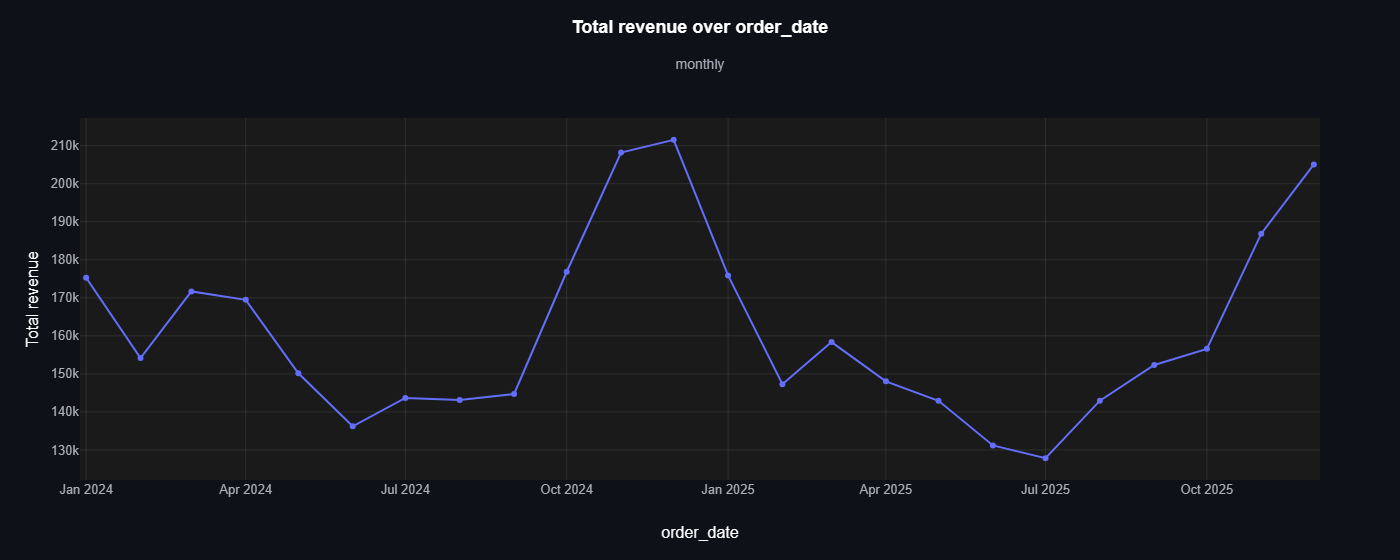

In [8]:
ev.line_plot(orders, "order_date", "revenue", agg="sum", time_grain="month")

`agg="count"` counts rows and needs no `y`: orders per week. The last week holds only
three days (Monday 29 to Wednesday 31 December 2025), which is why it seems to
collapse: a partial period at the edge of the data, best filtered in the query before
a report.

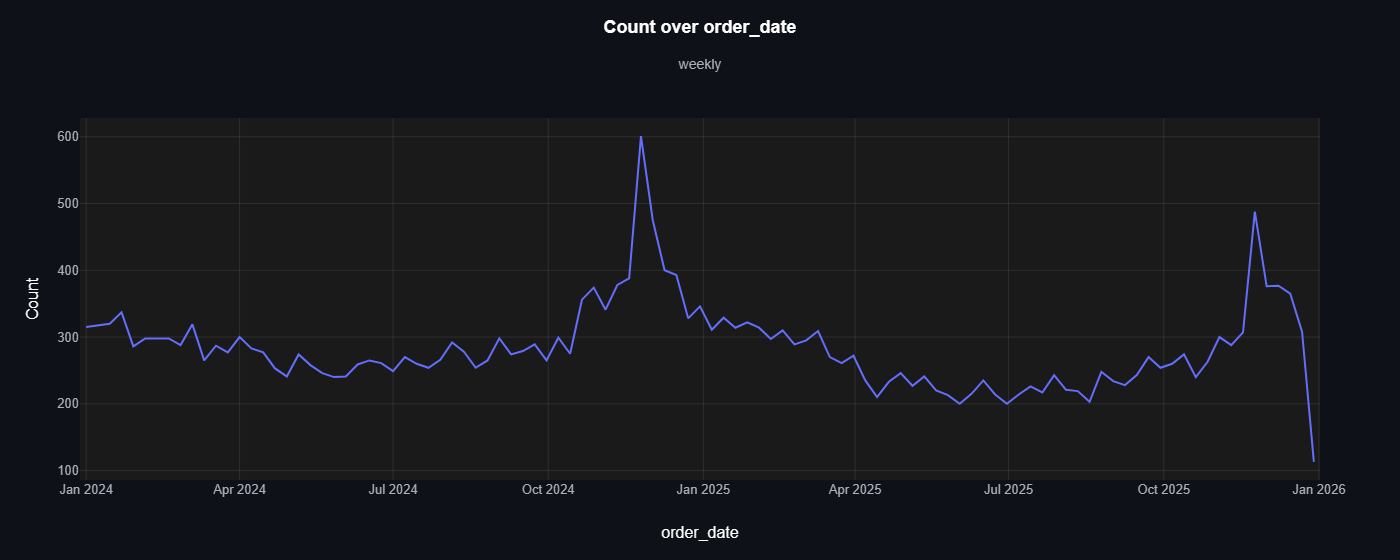

In [9]:
ev.line_plot(orders, "order_date", agg="count", time_grain="week")

The default `"auto"` reads the grain from the dates: the output of
`date_trunc('week', ...)` is weekly. Gifts, a long-tail category (*Long-tail product
categories*, pattern 5), has 305 orders in two years and no order at all in 10 of the
105 weeks, so the weekly `GROUP BY` returns no row for those weeks. The line breaks
there instead of bridging them, and a warning says how many weeks are empty.

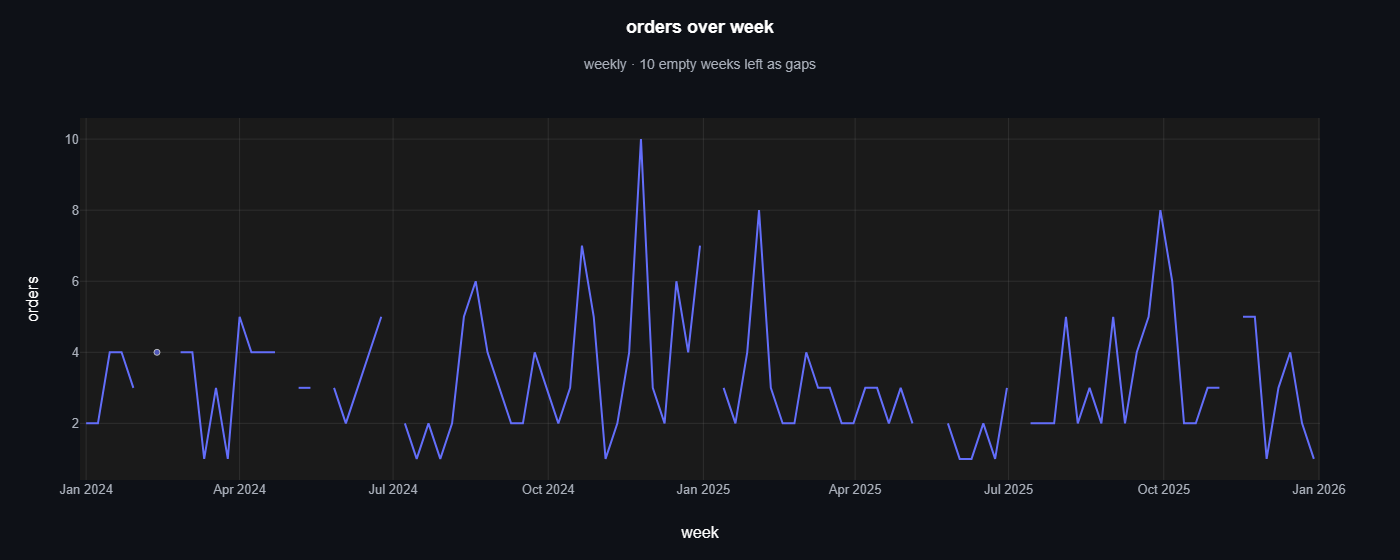

In [10]:
gifts = db.sql("""
    SELECT date_trunc('week', order_date) AS week,
           COUNT(*)     AS orders,
           AVG(revenue) AS order_value
    FROM orders JOIN products USING (product_id)
    WHERE category = 'Gifts'
    GROUP BY week
    ORDER BY week
""").pl()

ev.line_plot(gifts, "week", "orders")

`None` draws the points as they are, with no calendar. That is what most charting
tools do with this query: the line bridges every empty week, as if Gifts sold on, and
nothing says so.

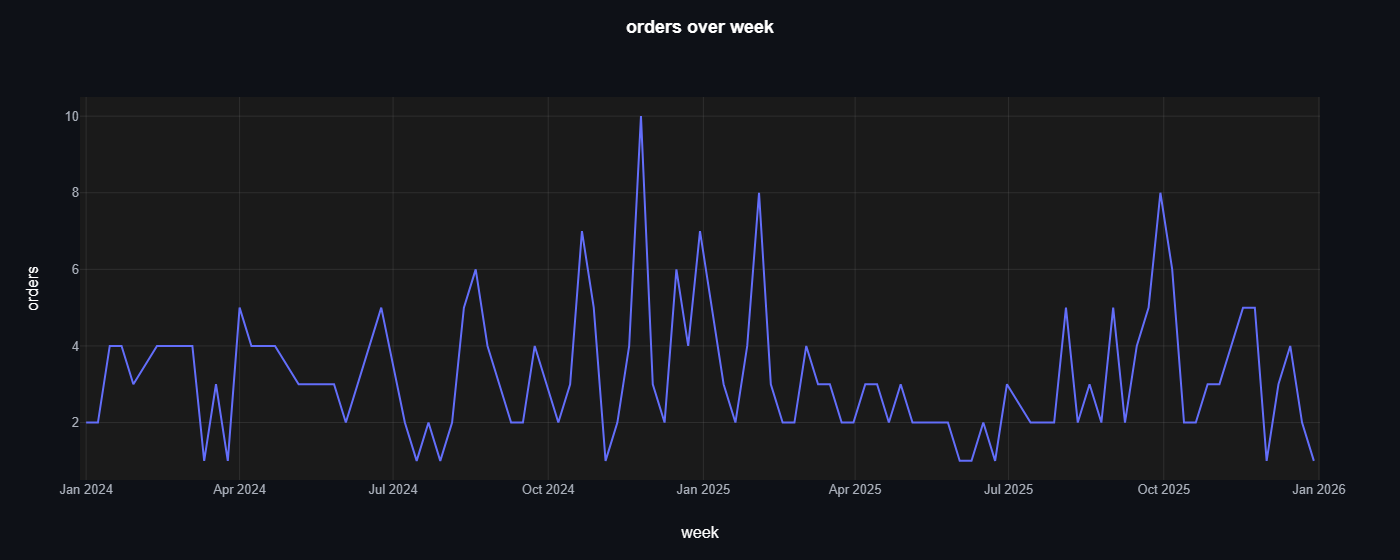

In [11]:
ev.line_plot(gifts, "week", "orders", time_grain=None)

**`missing_periods`** (`{"gap", "zero", "connect"} or None, default None`): how a
period of the calendar without a row is drawn. `None` draws gaps and warns how many
periods are empty. `"gap"` breaks the line the same way, without the warning: the
choice is now explicit.

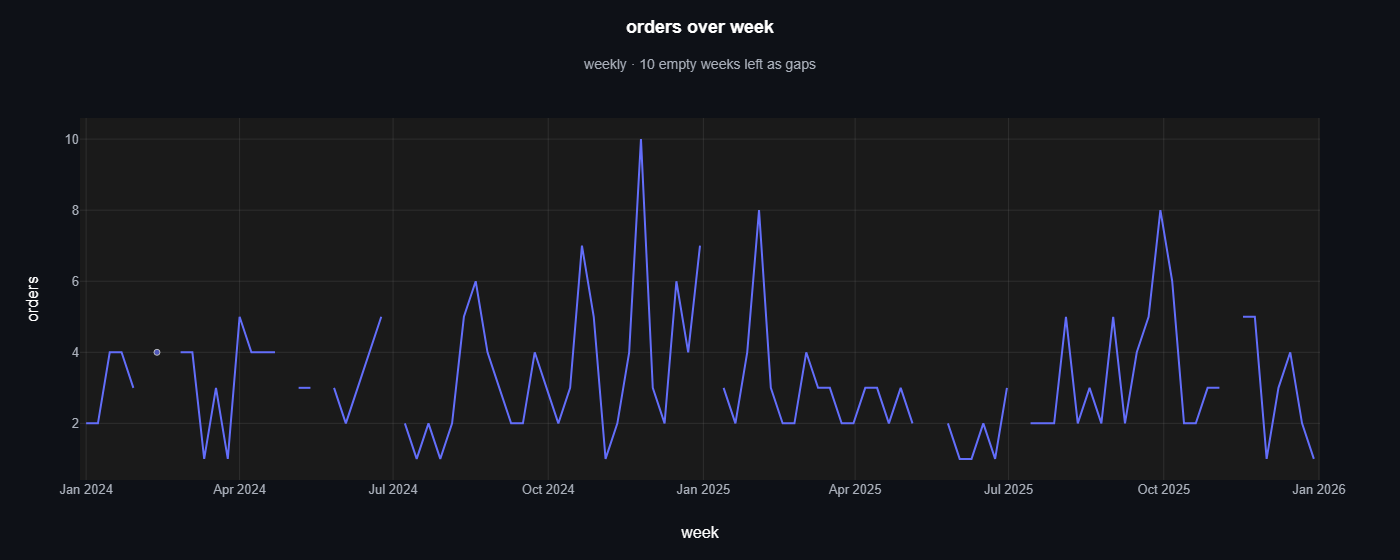

In [12]:
ev.line_plot(gifts, "week", "orders", missing_periods="gap")

`"zero"` draws 0: right for counts and sums, since no orders is zero orders.

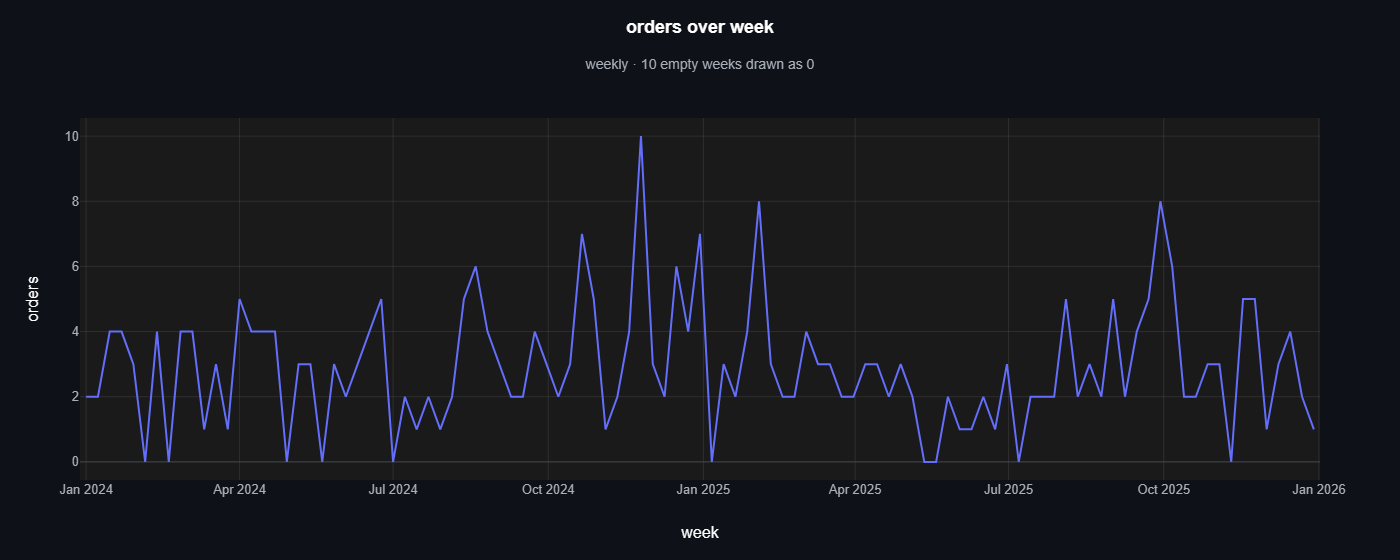

In [13]:
ev.line_plot(gifts, "week", "orders", missing_periods="zero")

`"connect"` bridges them, with points only where data exists: right for an average,
which has no value in an empty week rather than a value of 0. The mean Gifts order
value per week:

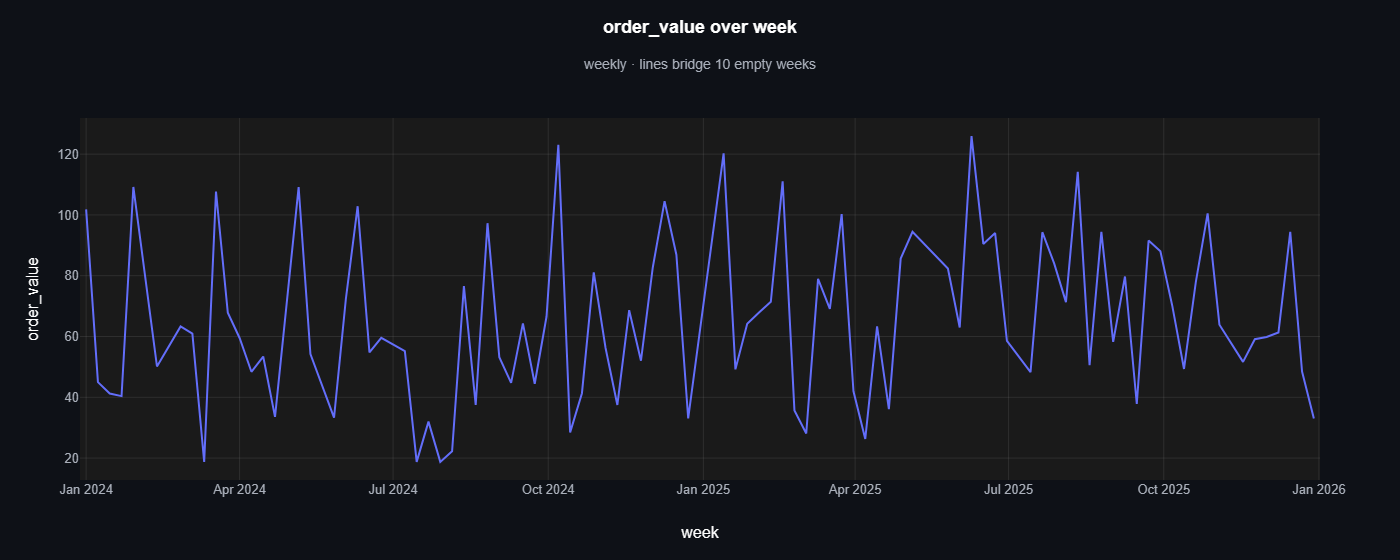

In [14]:
ev.line_plot(gifts, "week", "order_value", missing_periods="connect")

### Statistics

**`ci`** (`{"bootstrap", "sem"} or None, default None`): a shaded confidence band
around each line. `"bootstrap"` works for the mean and the median, `"sem"` (mean ±
z·standard error) for the mean only. It needs the raw rows behind each point, so
`agg="mean"` or `"median"`. The mean order value per month: the band shows how far
each month's mean could move by chance, about ±12 a month, as much as most of the
month-to-month wiggles.

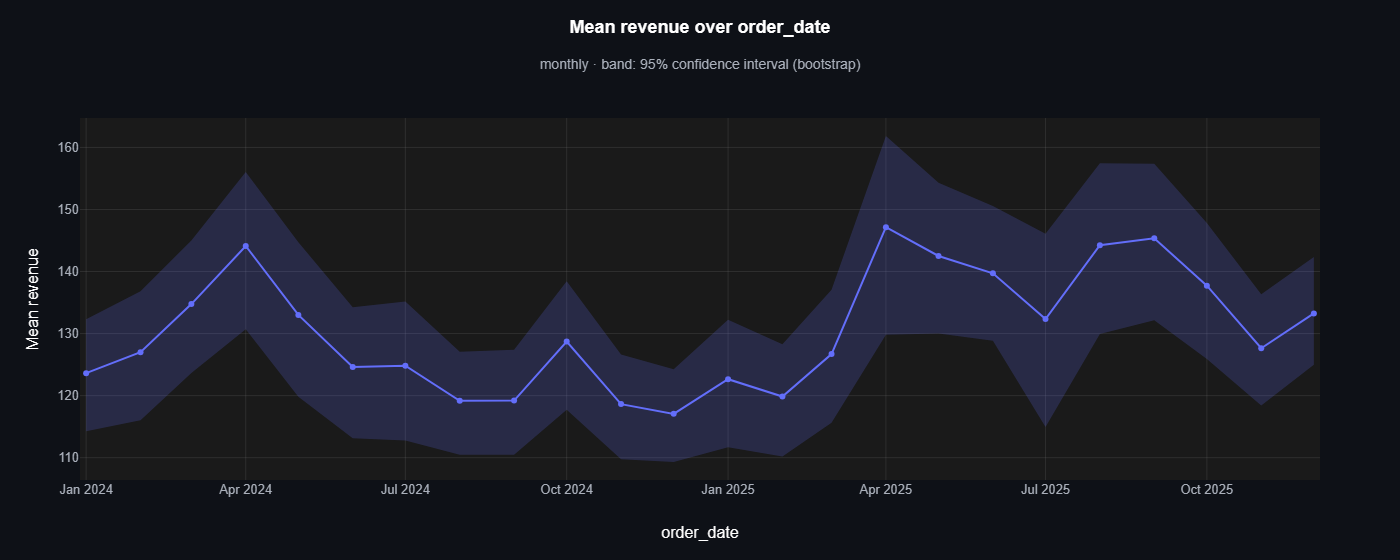

In [15]:
ev.line_plot(
    orders, "order_date", "revenue", agg="mean", time_grain="month", ci="bootstrap"
)

**`ci_level`** (`float, default 0.95`): the confidence level, strictly between 0 and
1. A 90 % band from the standard error is narrower than the 95 % one above.

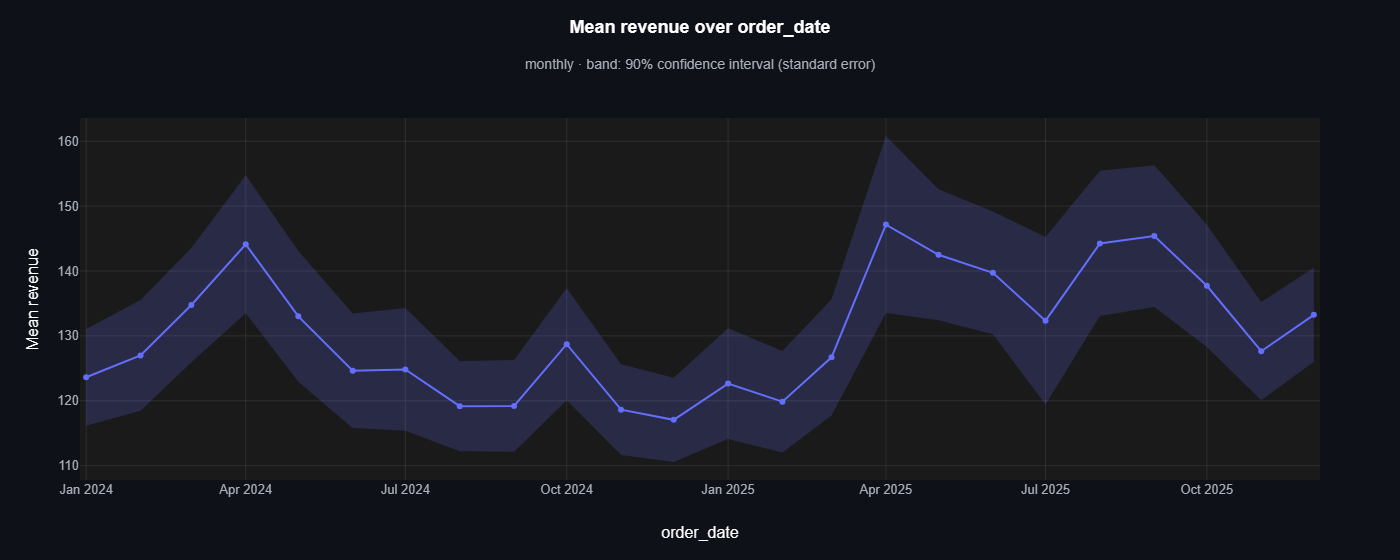

In [16]:
ev.line_plot(
    orders,
    "order_date",
    "revenue",
    agg="mean",
    time_grain="month",
    ci="sem",
    ci_level=0.9,
)

**`n_boot`** (`int, default 2000`): bootstrap resamples per point (`ci="bootstrap"`
only). **`random_state`** (`int, numpy Generator or None, default 0`): the seed of the
bootstrap. The fixed default draws the same band on every run; `None` draws a new one.
The median order value per quarter, with more resamples and another seed:

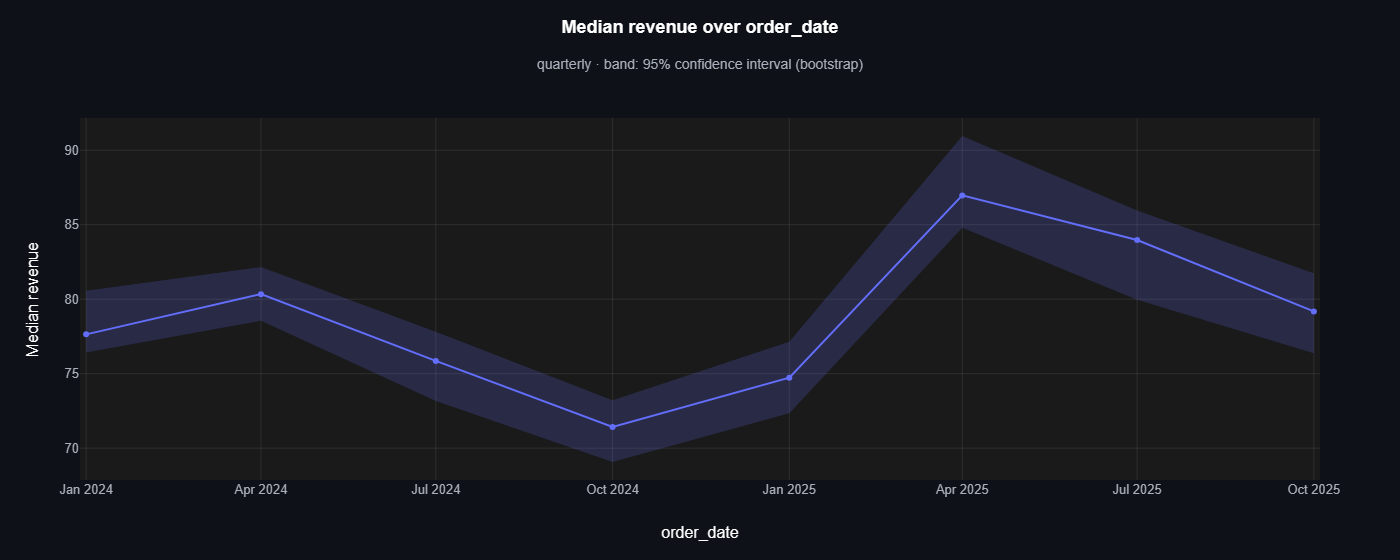

In [17]:
ev.line_plot(
    orders,
    "order_date",
    "revenue",
    agg="median",
    time_grain="quarter",
    ci="bootstrap",
    n_boot=5_000,
    random_state=42,
)

**`rolling`** (`int or None, default None`): the trailing mean over this many periods
(or points, without a calendar), drawn over each line; the raw line stays, faded. On a
calendar the window counts periods, so `rolling=28` on daily data is always 28 days,
also across empty ones. Site traffic smoothed over four weeks: a yearly wave and the
Black Friday rush, at the same level in 2025 as in 2024.

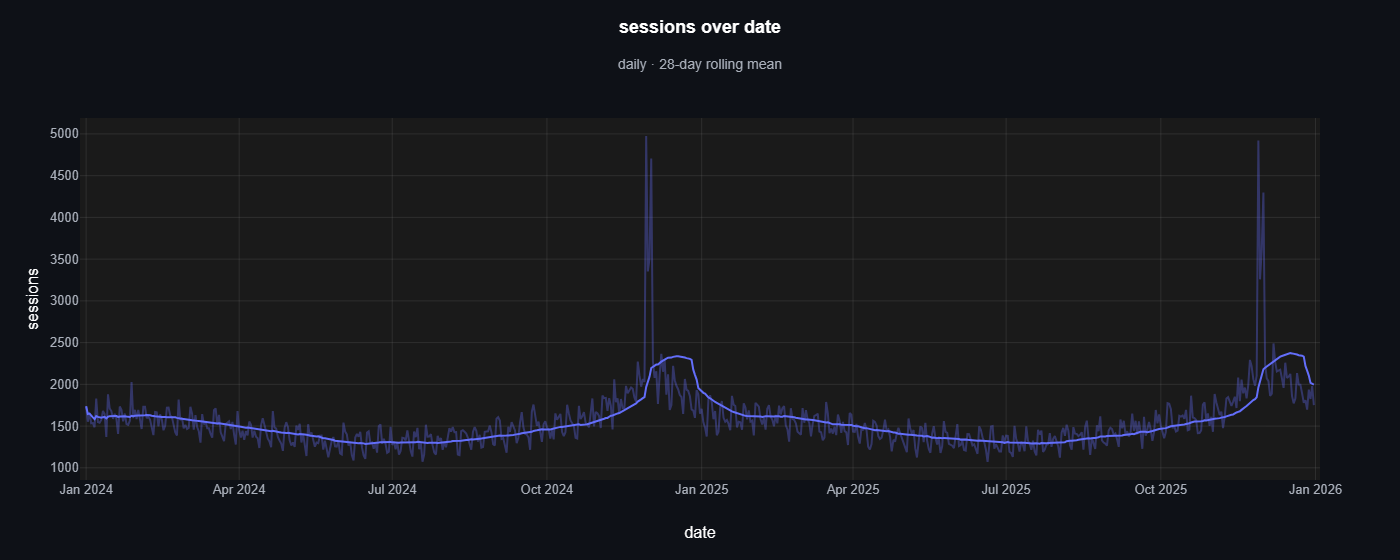

In [18]:
ev.line_plot(daily, "date", "sessions", rolling=28)

### Lines and markers

**`show_markers`** (`bool or None, default None`): markers on the data points.
`None`: markers when no series has more than 30 points, so the 24 months above have
them and the 731 days don't. Turned off:

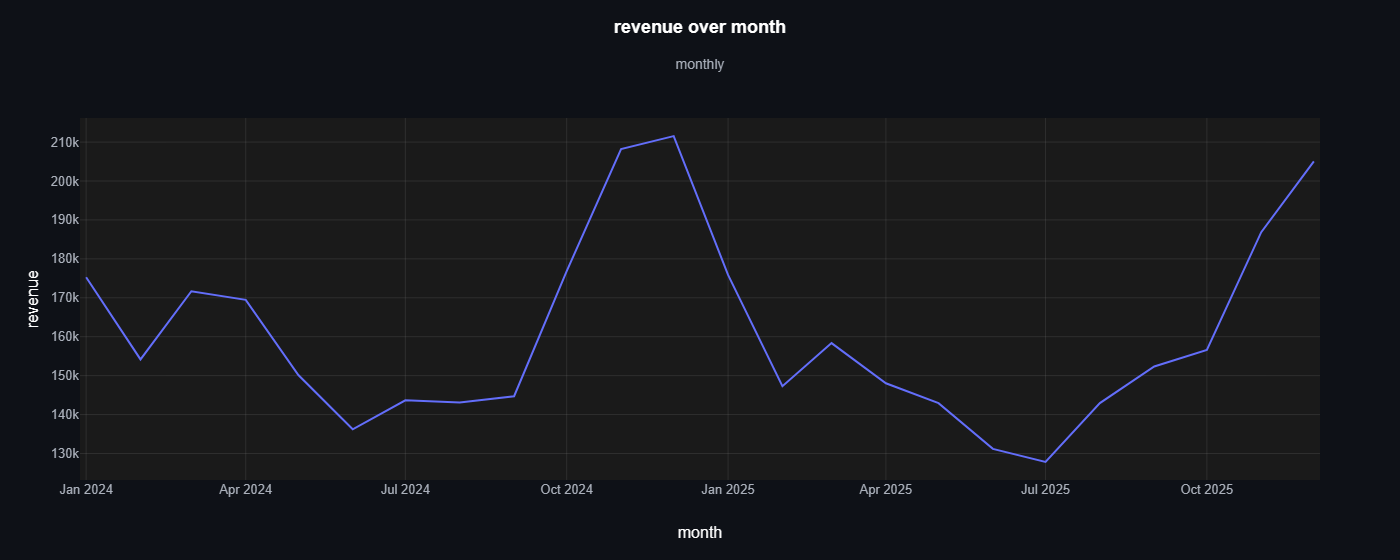

In [19]:
ev.line_plot(monthly, "month", "revenue", show_markers=False)

**`line_shape`** (`{"linear", "spline", "hv", "vh", "hvh", "vhv"}, default "linear"`):
how the line runs between points: straight, smoothed, or in steps. `"spline"` curves
through every point, and can bulge slightly past a point between two steep ones, so
read values from the hover. The steps (`"hv"` holds each value until the next point)
suit a value that stays put until it changes, such as a price.

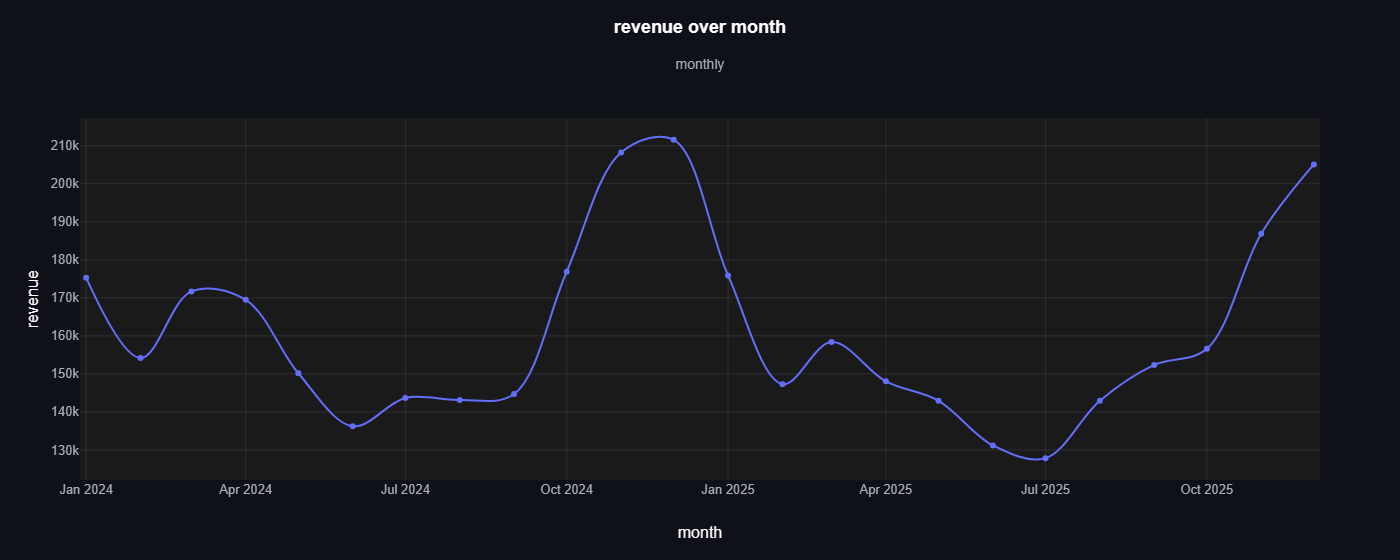

In [20]:
ev.line_plot(monthly, "month", "revenue", line_shape="spline")

**`fill_area`** (`bool, default False`): shade the area between each line and zero.
The axis then starts at zero, which shows the swings against the whole.

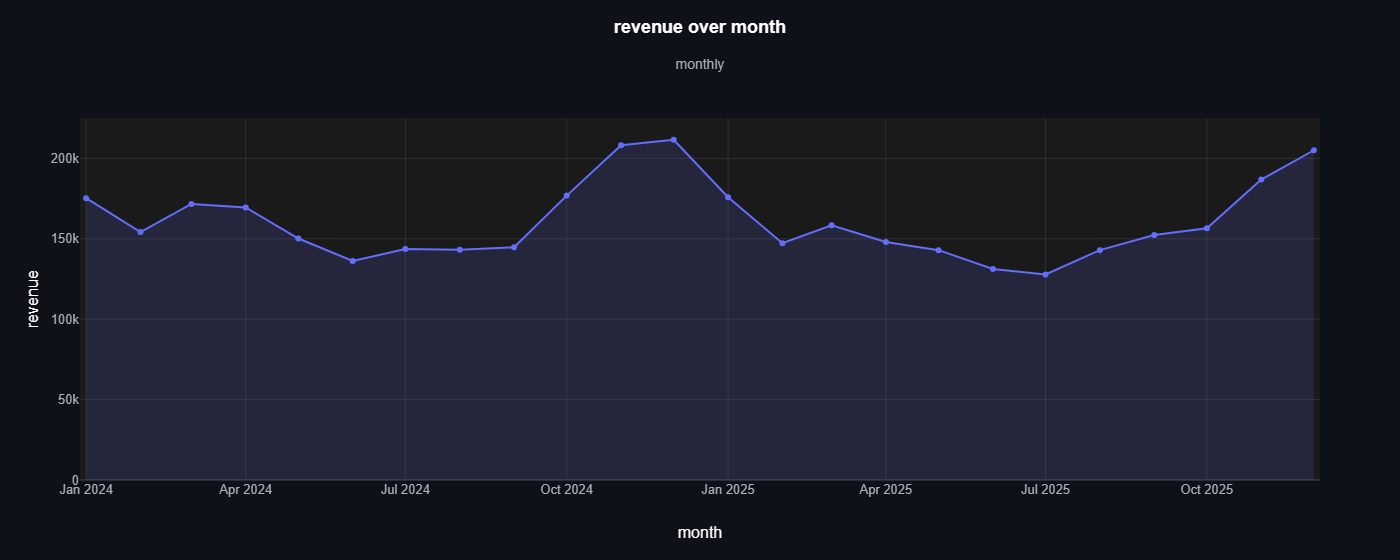

In [21]:
ev.line_plot(monthly, "month", "revenue", fill_area=True)

### Labels

**`show_values`** (`bool or {"last", "ends", "extremes"}, default False`): write
values on the line the reader follows (the rolling mean when `rolling` is set). `True`
labels every point: here, revenue per quarter. Each label sits on the side of its
point away from the line, and the labels at the two ends lean inward, clear of the
axis.

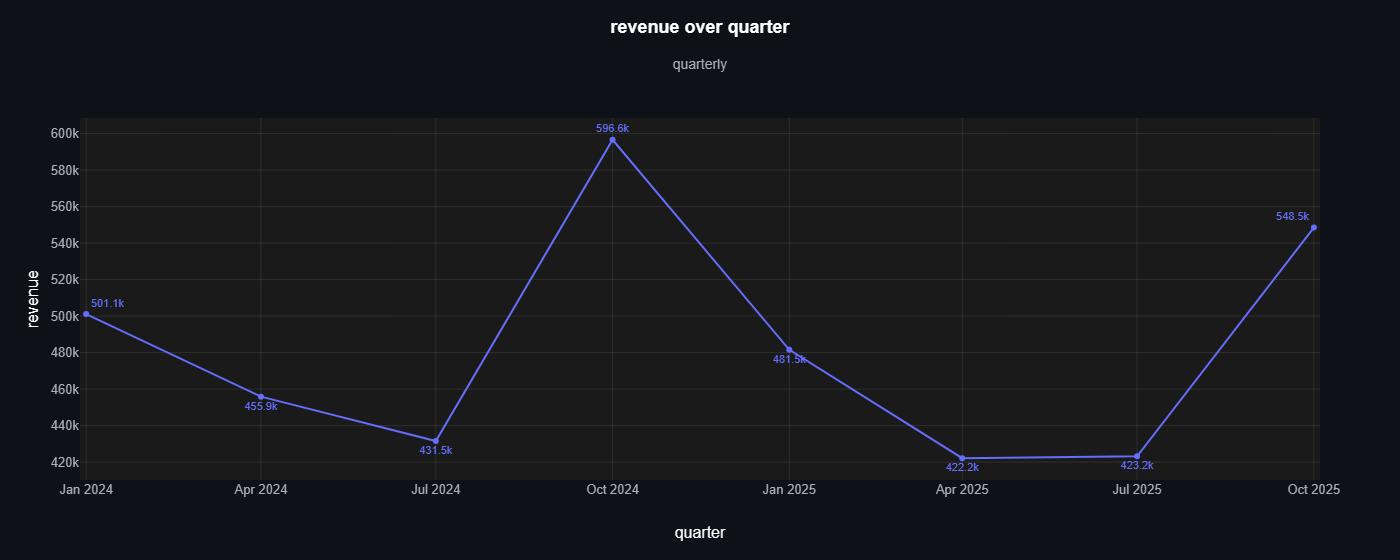

In [22]:
quarterly = db.sql("""
    SELECT date_trunc('quarter', order_date) AS quarter, SUM(revenue) AS revenue
    FROM orders
    GROUP BY quarter
    ORDER BY quarter
""").pl()

ev.line_plot(quarterly, "quarter", "revenue", show_values=True)

`"last"` labels the last point of each line: where each series ended.

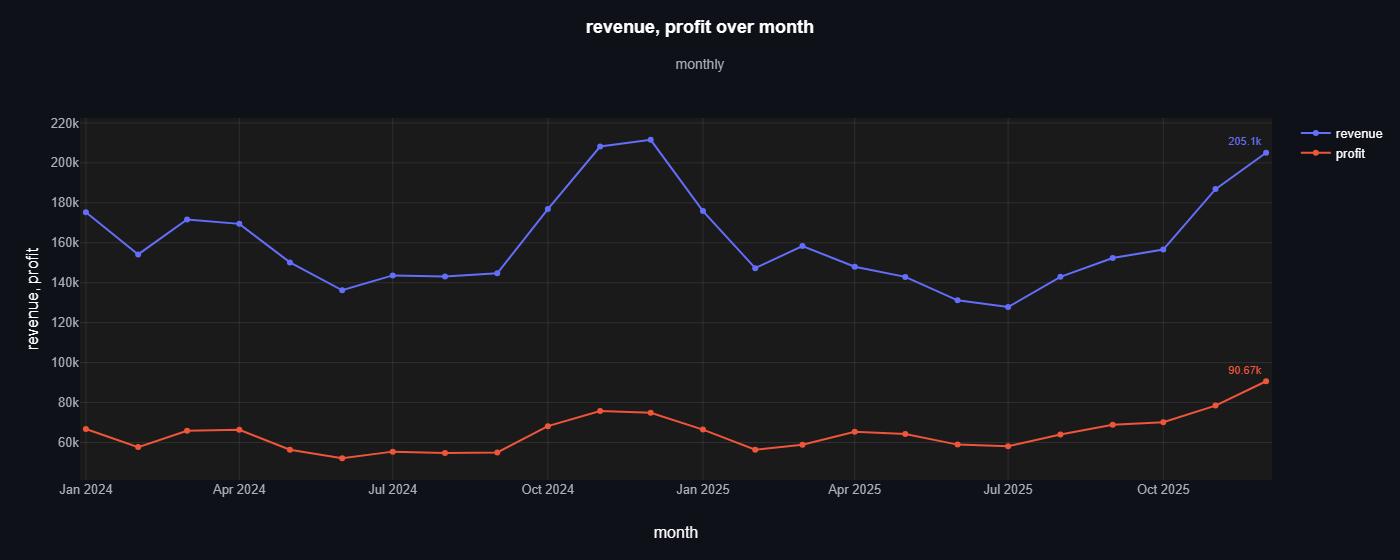

In [23]:
ev.line_plot(monthly, "month", ["revenue", "profit"], show_values="last")

`"ends"` labels the first and the last point: where the line started and where it
ended.

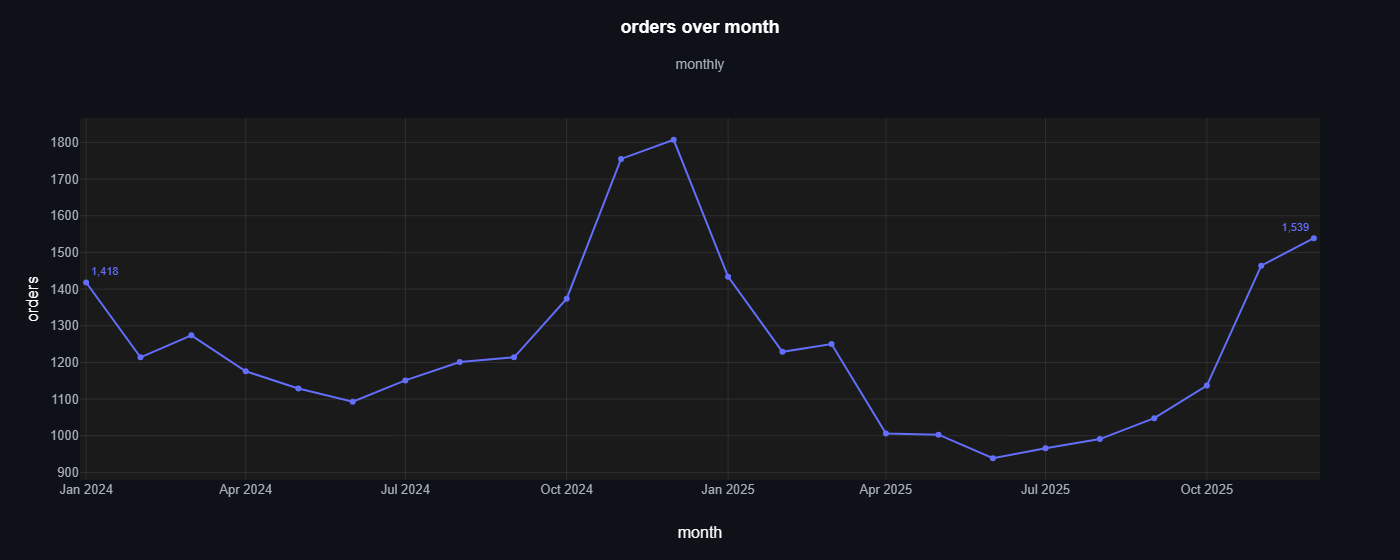

In [24]:
ev.line_plot(monthly, "month", "orders", show_values="ends")

`"extremes"` labels each series' max (above) and min (below).

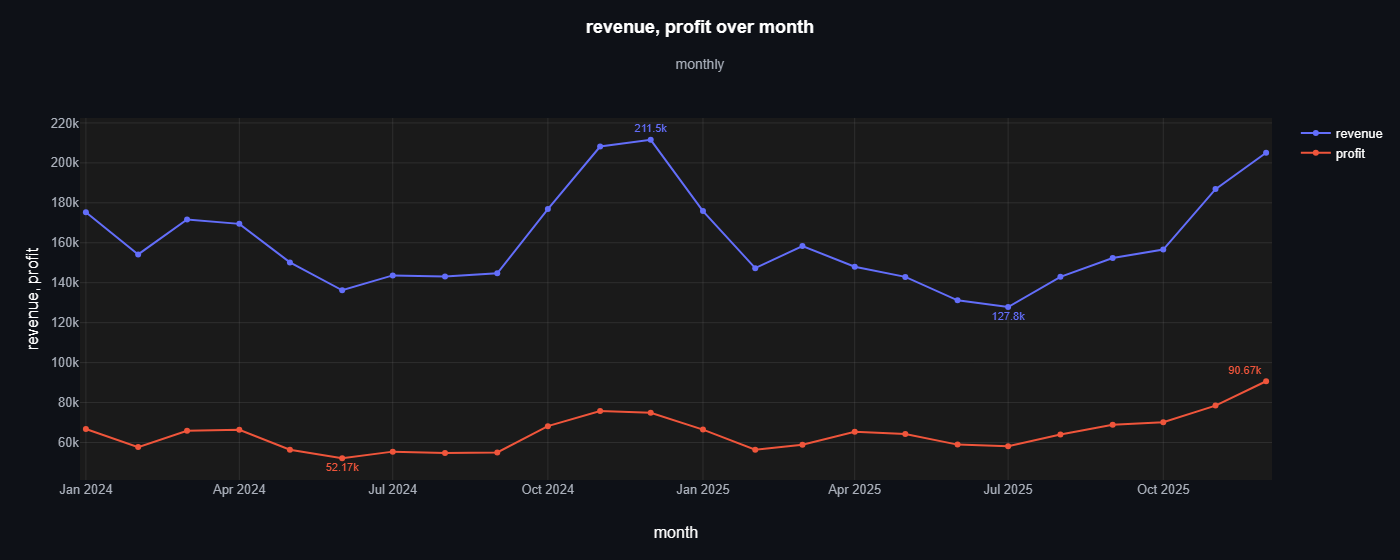

In [25]:
ev.line_plot(monthly, "month", ["revenue", "profit"], show_values="extremes")

**`value_format`** (`str or None, default None`): a Python format spec for values in
labels, hover and reference lines, e.g. `",.0f"` or `".1%"`. `None`: four significant
digits with k, M, B for thousands, millions, billions. A conversion rate, per month
from the daily metrics, reads best as a percentage:

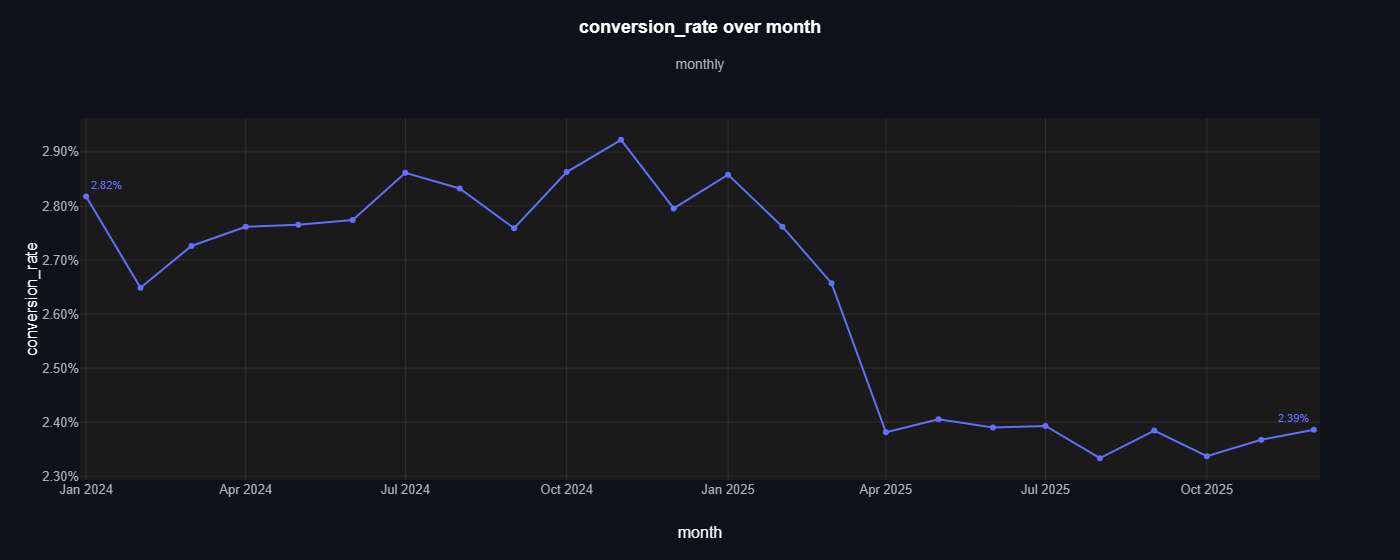

In [26]:
kpis = db.sql("""
    SELECT date_trunc('month', date) AS month,
           SUM(orders) / SUM(sessions) AS conversion_rate,
           SUM(revenue) / SUM(orders)  AS avg_order_value
    FROM daily_metrics
    GROUP BY month
    ORDER BY month
""").pl()

ev.line_plot(kpis, "month", "conversion_rate", show_values="ends", value_format=".2%")

### Colour

**`highlight`** (`str, list of str or None, default None`): series to emphasise
(`color` values or `y` columns). They keep their colours and are drawn slightly
heavier, on top; the others use the theme's dimmed colour. Monthly revenue of all 18
categories, with the two biggest highlighted. The dimmed lines share one legend entry,
"16 others", which shows or hides them all at once.

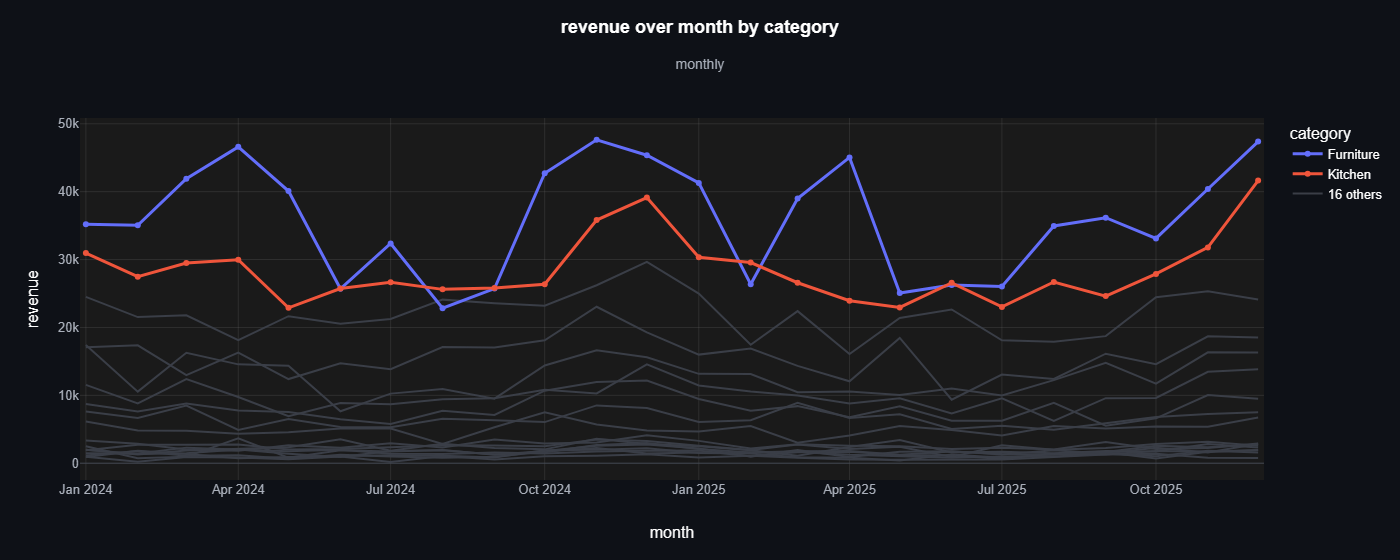

In [27]:
by_category = db.sql("""
    SELECT date_trunc('month', order_date) AS month, category, SUM(revenue) AS revenue
    FROM orders JOIN products USING (product_id)
    GROUP BY month, category
    ORDER BY month, category
""").pl()

ev.line_plot(
    by_category,
    "month",
    "revenue",
    color="category",
    highlight=["Furniture", "Kitchen"],
)

**`color_map`** (`mapping of str to str or None, default None`): a fixed colour per
series, so a series looks the same in every chart. Hex, `rgb()` or `rgba()`; it must
cover every series drawn in colour (the highlighted ones, with `highlight`) and may
hold others, so one map can serve a whole report.

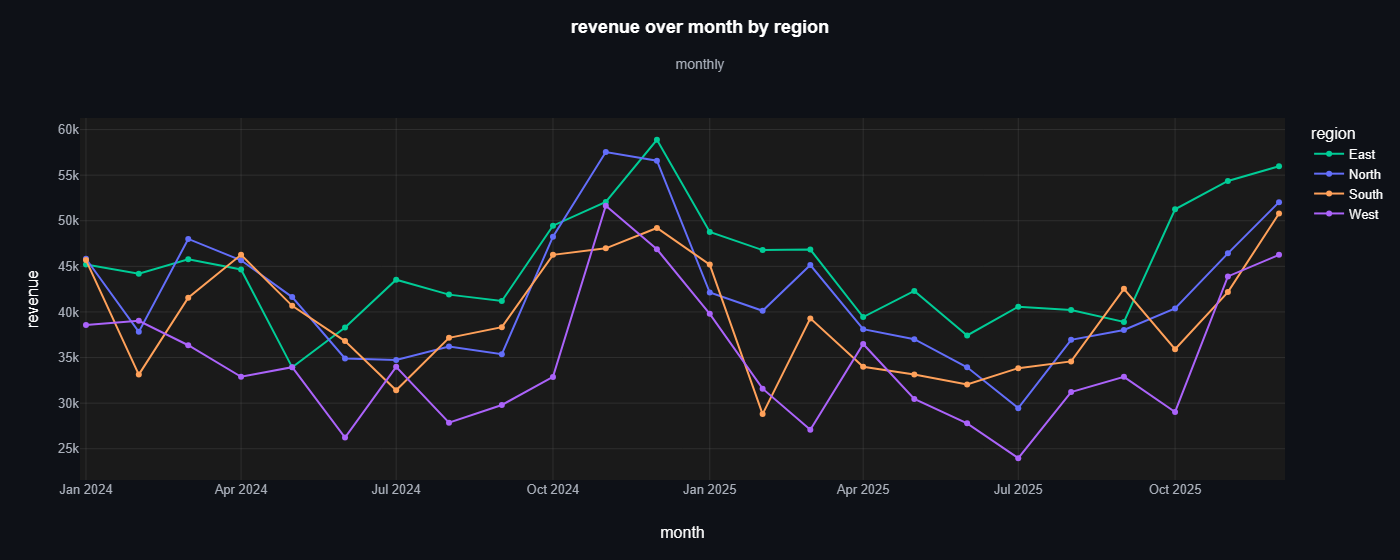

In [28]:
REGION_COLORS = {
    "North": "#636EFA",
    "East": "#00CC96",
    "South": "#FFA15A",
    "West": "#AB63FA",
}

ev.line_plot(by_region, "month", "revenue", color="region", color_map=REGION_COLORS)

### Reference lines

**`overall_line`** (`bool, default False`): one extra, heavier line in the theme's
neutral colour: all series together at each `x`. With `agg`, the same aggregate over
every row at that `x` ("Overall": a true total, mean, median or count). Mean delivery
days per month for the two warehouses (*Hidden bimodality: two warehouses*, pattern
3): the North hub delivers in about 2 days, the South hub in about 5.5, and the
overall mean of all orders, 3.6 days, is a delivery time almost no order has.

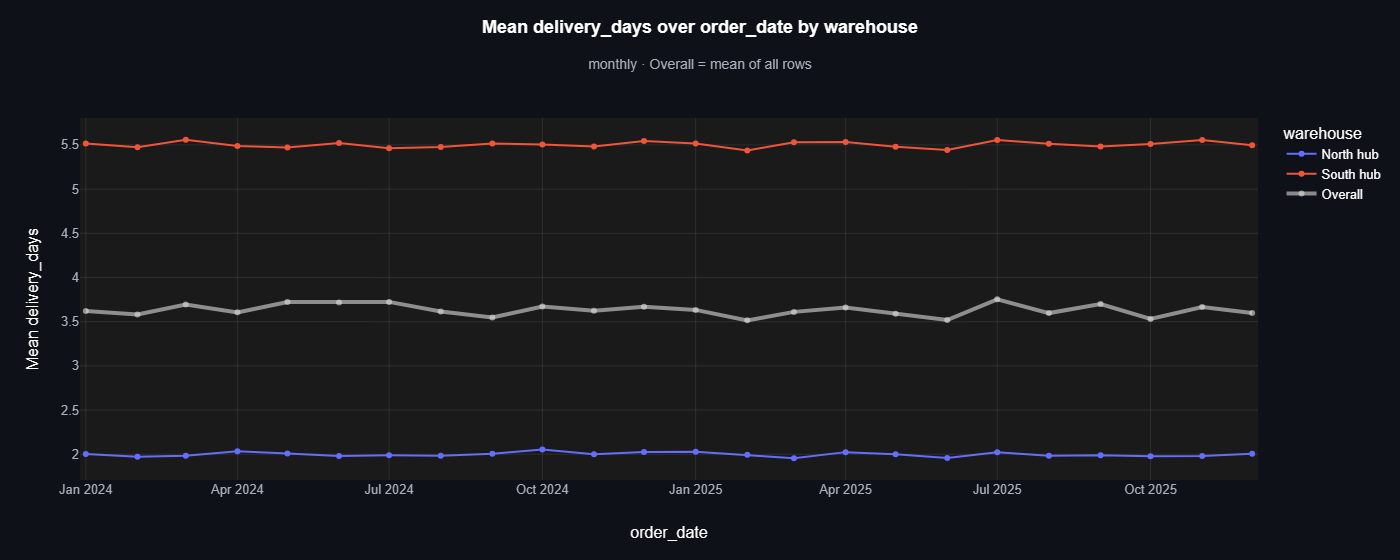

In [29]:
ev.line_plot(
    orders,
    "order_date",
    "delivery_days",
    color="warehouse",
    agg="mean",
    time_grain="month",
    overall_line=True,
)

With `agg=None` the raw rows aren't there to recompute it, so the extra line is only
the mean of the series' values, named "Mean of series" in the legend and the subtitle.
From a query that already averaged per month and warehouse it sits near 3.75 days,
above the true 3.6: the North hub ships more of the orders, which an average of the
two lines can't know. That is why it carries another name.

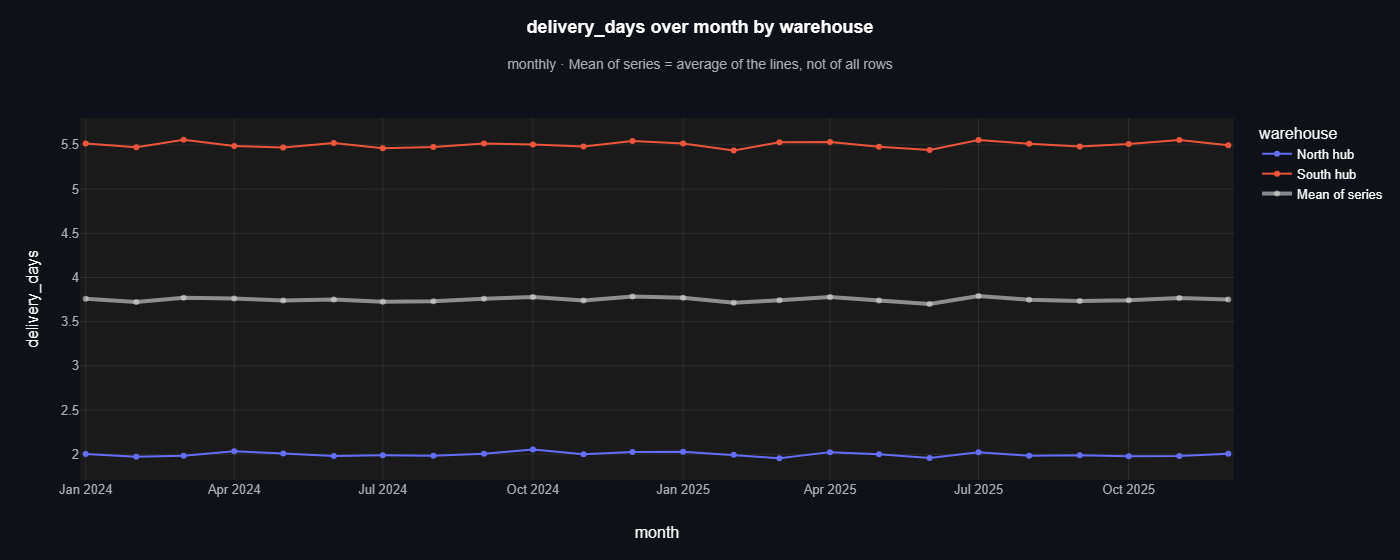

In [30]:
delivery = db.sql("""
    SELECT date_trunc('month', order_date) AS month, warehouse,
           AVG(delivery_days) AS delivery_days
    FROM orders
    GROUP BY month, warehouse
    ORDER BY month, warehouse
""").pl()

ev.line_plot(delivery, "month", "delivery_days", color="warehouse", overall_line=True)

**`avg_line`** (`bool, default False`): a dashed line at the mean of every point
drawn, all series together.

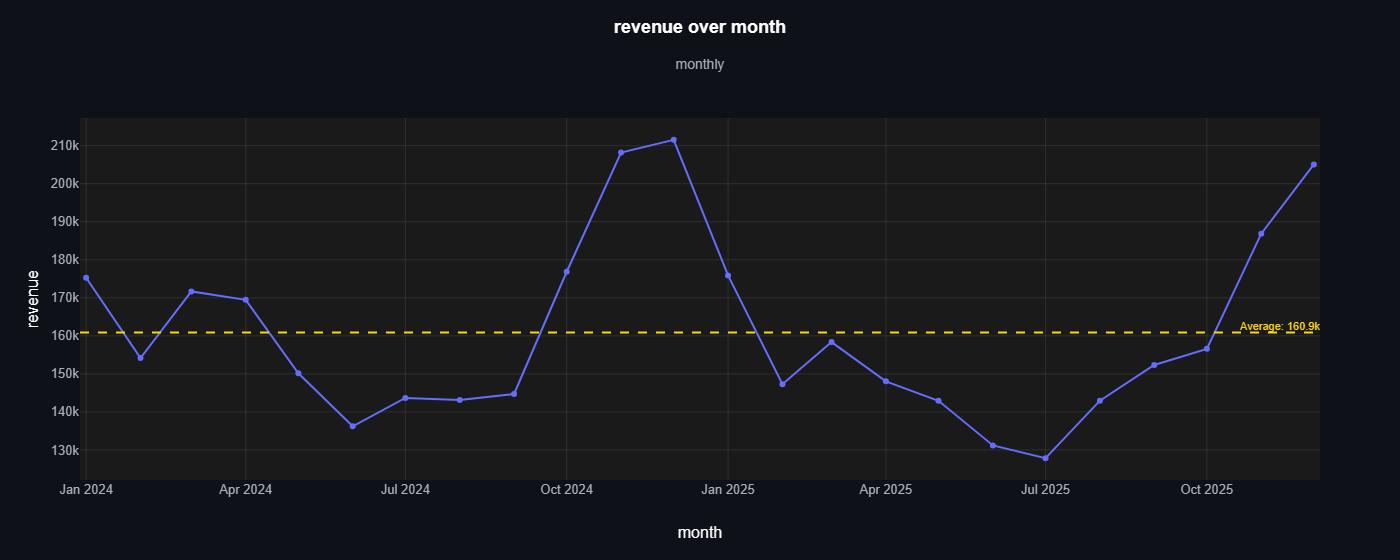

In [31]:
ev.line_plot(monthly, "month", "revenue", avg_line=True)

**`target`** (`float or None, default None`): a dotted line at a target value,
labelled. The monthly conversion rate against a 2.5 % goal:

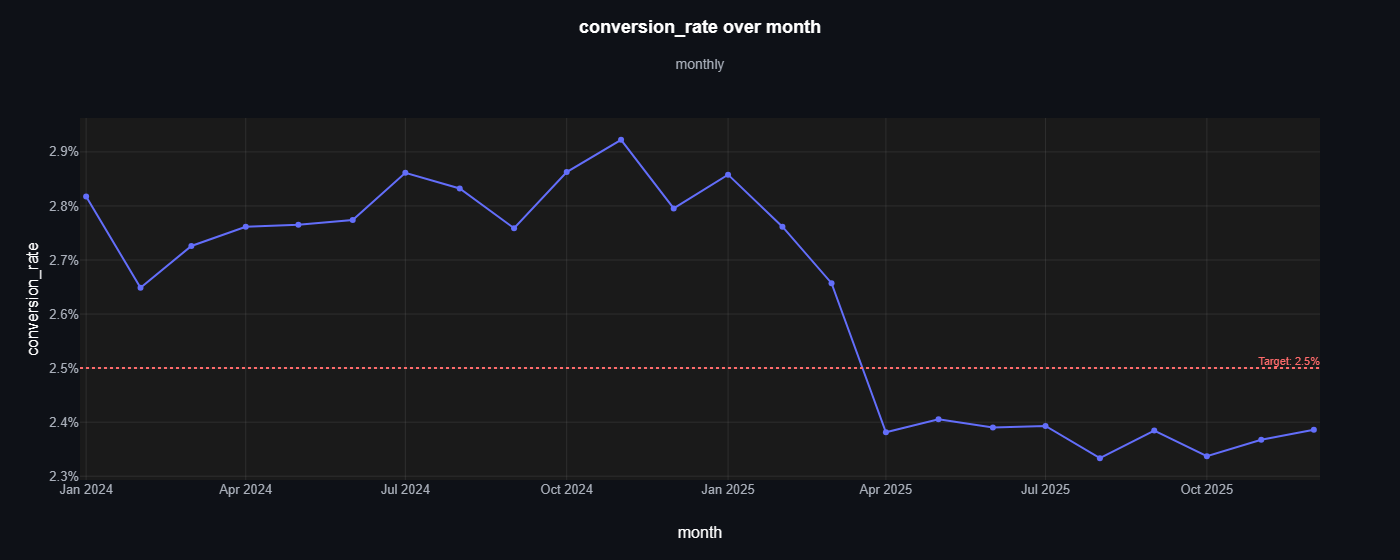

In [32]:
ev.line_plot(kpis, "month", "conversion_rate", target=0.025, value_format=".1%")

**`events`** (`mapping of x value to str, or None, default None`): labelled vertical
lines at given `x` values. Keys are ISO-date strings, dates or datetimes for a time
`x`, numbers for a numeric `x`, categories for a text `x`; each must lie within the
drawn `x` range. Both Black Fridays, on daily orders smoothed over a week:

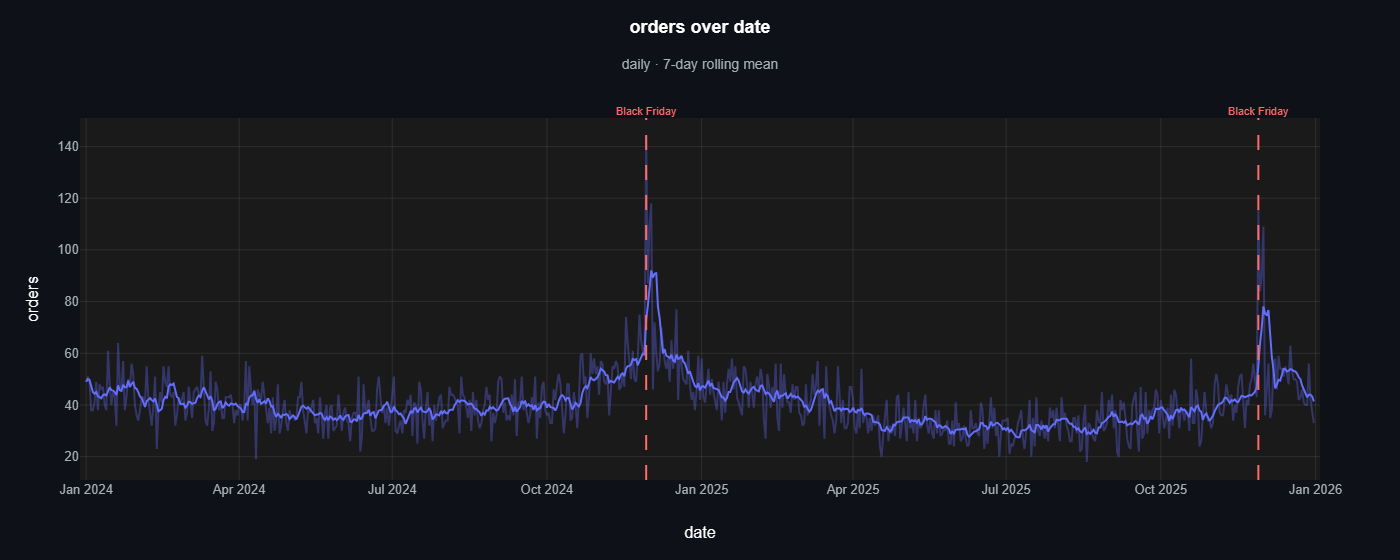

In [33]:
ev.line_plot(
    daily,
    "date",
    "orders",
    rolling=7,
    events={"2024-11-29": "Black Friday", "2025-11-28": "Black Friday"},
)

### Axes and layout

**A text `x`** keeps the query's order (`ORDER BY`), so weekdays run Monday to Sunday
instead of alphabetically. Mean daily orders per weekday, per year: Sunday and Monday
are the busiest days, Saturday the quietest (the weekly cycle of pattern 4), and 2025
sits lower on every day.

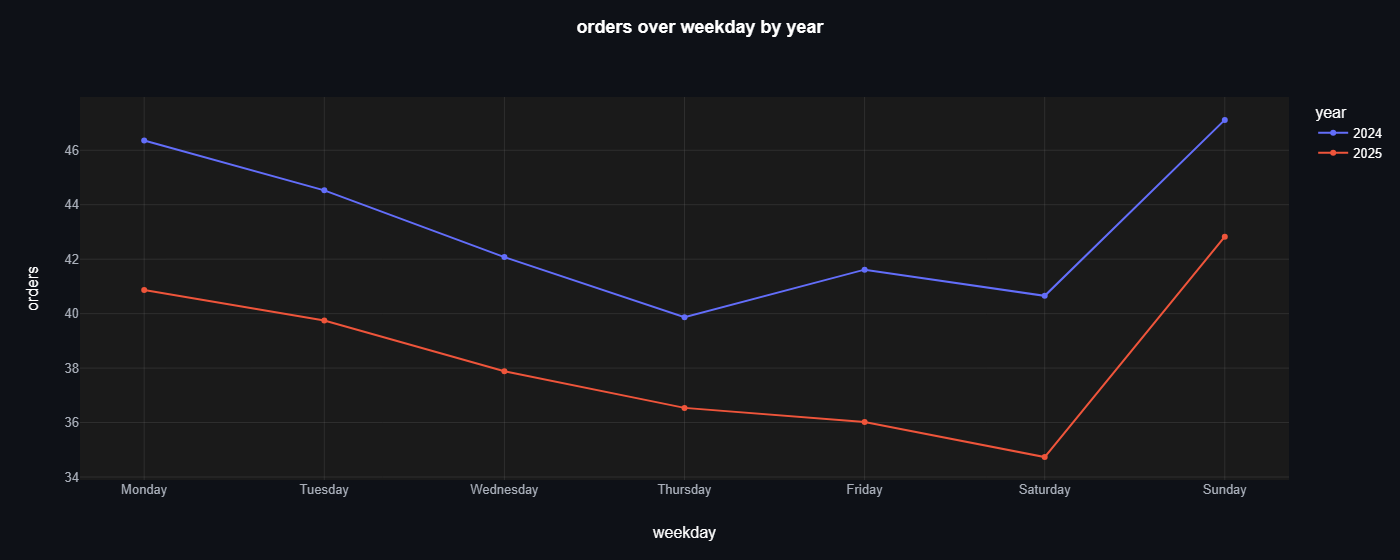

In [34]:
weekdays = db.sql("""
    SELECT dayname(date) AS weekday, year(date)::VARCHAR AS year, AVG(orders) AS orders
    FROM daily_metrics
    GROUP BY weekday, isodow(date), year
    ORDER BY year, isodow(date)
""").pl()

ev.line_plot(weekdays, "weekday", "orders", color="year")

**`log_x`** (`bool, default False`): log-scale the x axis. Needs a numeric `x`.
Customers ranked by profit, with the share of all profit the top ones bring
(*Profit concentration*, pattern 2). On a log axis the first ten customers get as much
room as the next ninety, and the curve reads off that the top 800 (20 %) bring about
three quarters of the profit.

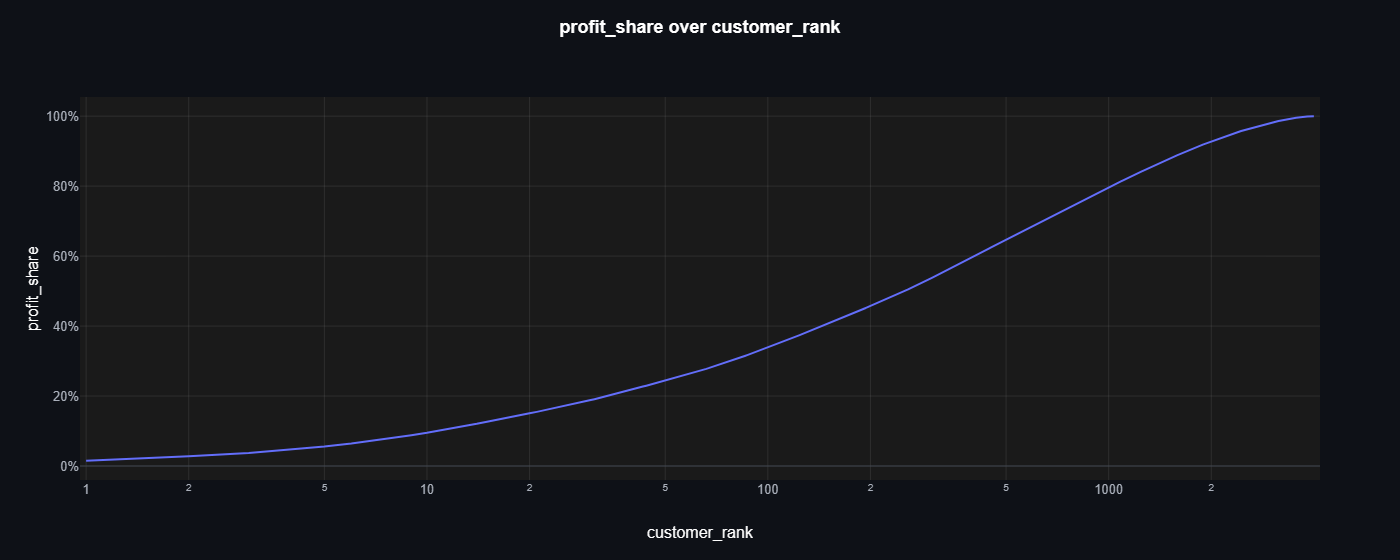

In [35]:
ranked = db.sql("""
    WITH per_customer AS (
        SELECT customer_id, SUM(profit) AS profit
        FROM orders
        GROUP BY customer_id
    )
    SELECT ROW_NUMBER() OVER (ORDER BY profit DESC, customer_id) AS customer_rank,
           SUM(profit) OVER (ORDER BY profit DESC, customer_id)
             / SUM(profit) OVER () AS profit_share
    FROM per_customer
    ORDER BY customer_rank
""").pl()

ev.line_plot(ranked, "customer_rank", "profit_share", log_x=True, value_format=".0%")

**`log_y`** (`bool, default False`): log-scale the y axis. Every value drawn must be
above 0, and so must both ends of a `ci` band (a band is never clipped: that would
misstate the interval) and a `target`. Kitchen sells about 30 times as much as Gifts;
on a log axis both lines show their shape, and equal distances mean equal percentage
changes.

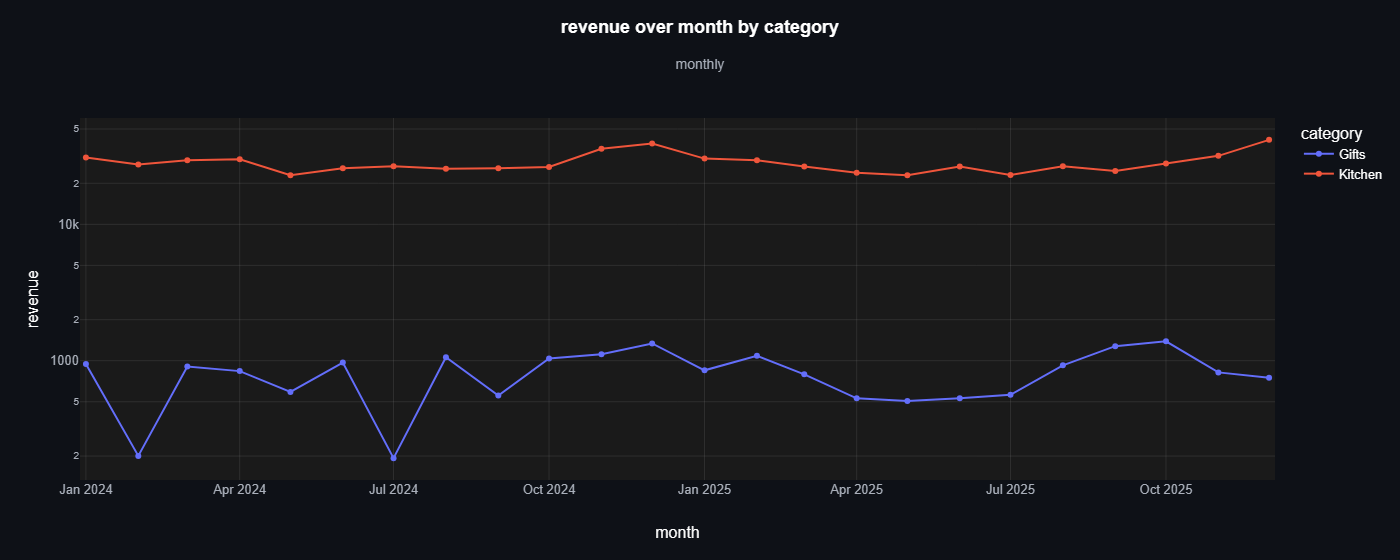

In [36]:
kitchen_gifts = db.sql("""
    SELECT date_trunc('month', order_date) AS month, category, SUM(revenue) AS revenue
    FROM orders JOIN products USING (product_id)
    WHERE category IN ('Kitchen', 'Gifts')
    GROUP BY month, category
    ORDER BY month, category
""").pl()

ev.line_plot(kitchen_gifts, "month", "revenue", color="category", log_y=True)

**`rangeslider`** (`bool, default False`): a range slider under the x axis, to zoom
into a stretch of a long series. Needs a time or numeric `x`. Drag its handles in
Jupyter; the static image shows the whole range.

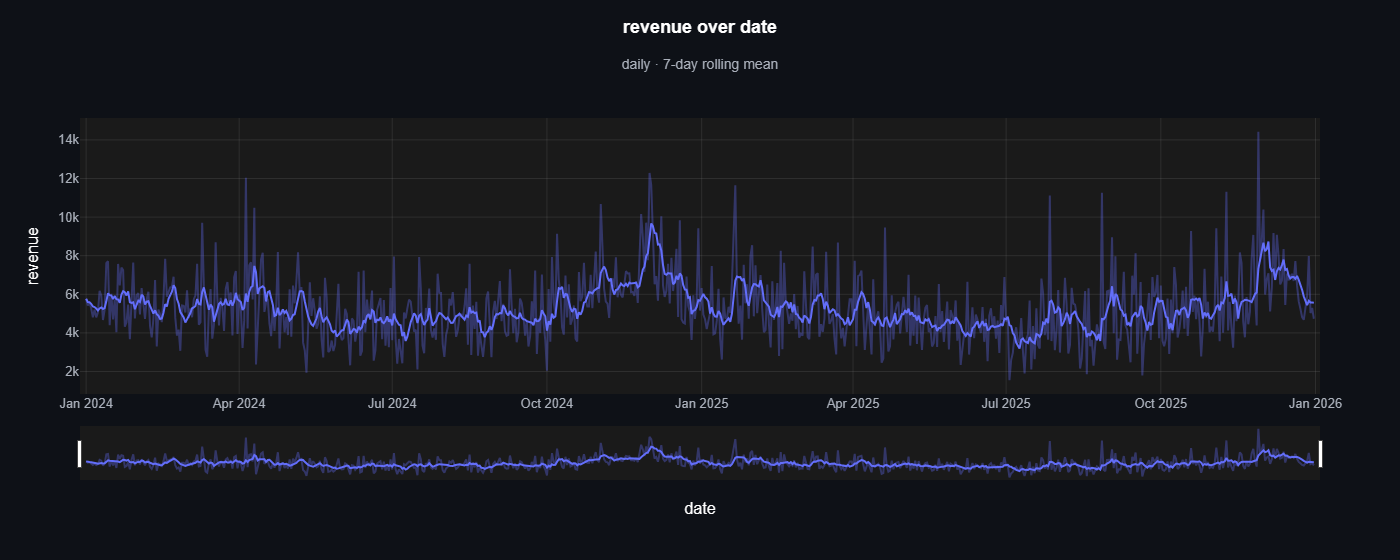

In [37]:
ev.line_plot(daily, "date", "revenue", rolling=7, rangeslider=True)

**`title`**, **`subtitle`** (`str or None, default None`): `None` builds them: the
title from the columns, the subtitle from what the chart does to the data (the
calendar grain, empty periods, the rolling window, the interval method, what the
overall line is). `""` shows none. A report title states the finding instead.
**`x_title`**, **`y_title`** (`str or None, default None`): axis titles; `None` uses
the column name (`y` with its aggregate), `""` shows none. **`width`**, **`height`**
(`int or None, default None`): size in px. `width=None` uses `ev.get_config().width`;
`height=None` is 0.4 x the width.

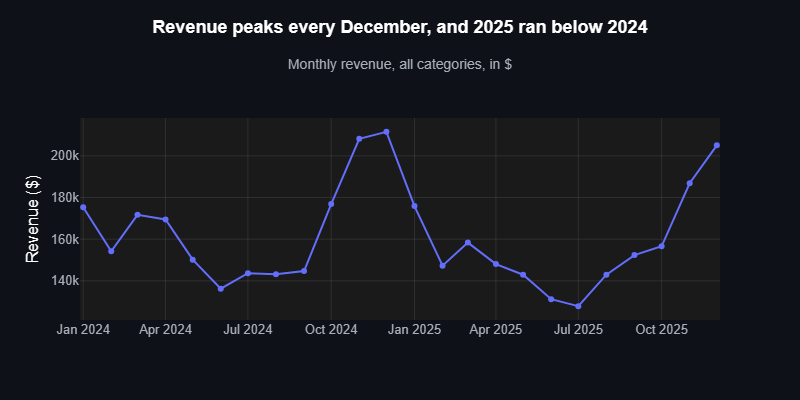

In [38]:
ev.line_plot(
    monthly,
    "month",
    "revenue",
    title="Revenue peaks every December, and 2025 ran below 2024",
    subtitle="Monthly revenue, all categories, in $",
    x_title="",
    y_title="Revenue ($)",
    width=800,
    height=400,
)

### Theme

**`theme`** (`{"dark", "light"}, Theme or None, default None`): the theme for this
chart; `None` uses the global one (`ev.set_theme`). Line width and marker size come
from it.

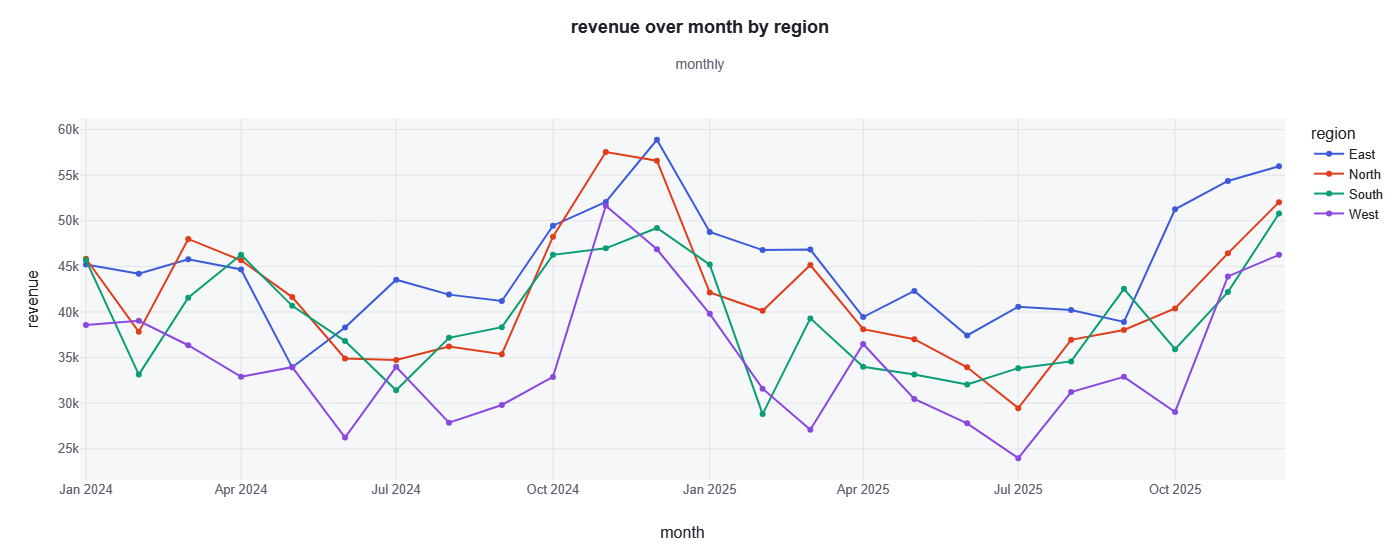

In [39]:
ev.line_plot(by_region, "month", "revenue", color="region", theme="light")

## Combinations

Professional charts take more options, never more code.

**Did conversion recover after the price rise?** Monthly conversion against a 2.5 %
goal, with the price rise marked and the best and worst month labelled.

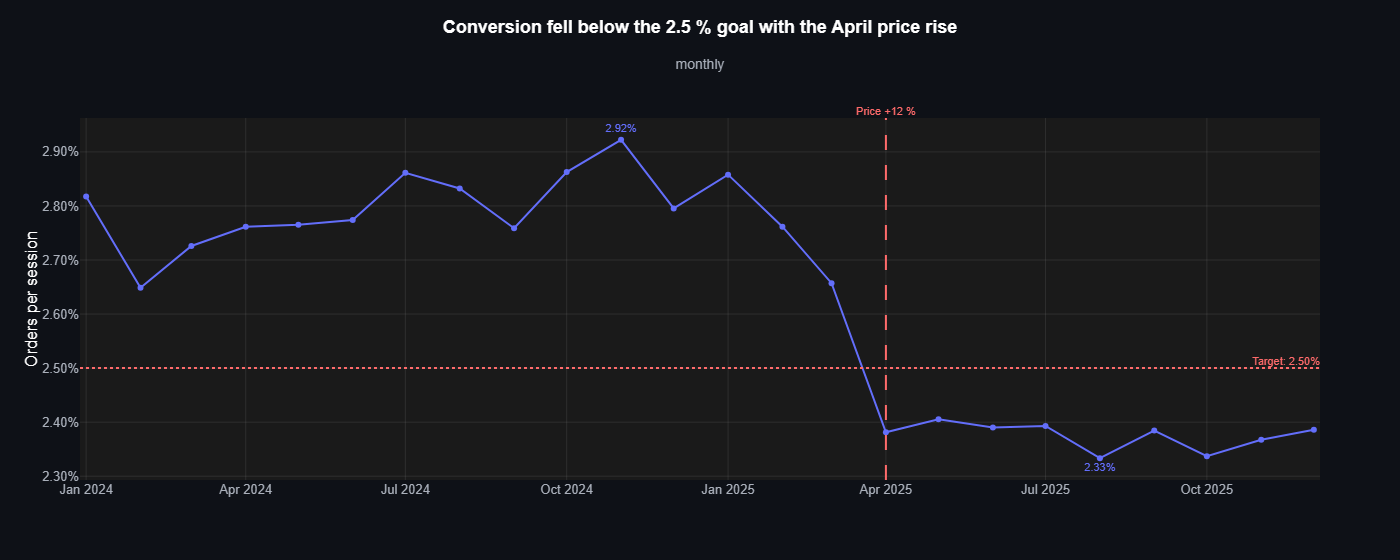

In [40]:
ev.line_plot(
    kpis,
    "month",
    "conversion_rate",
    show_values="extremes",
    value_format=".2%",
    target=0.025,
    events={"2025-04-01": "Price +12 %"},
    title="Conversion fell below the 2.5 % goal with the April price rise",
    x_title="",
    y_title="Orders per session",
)

**Does each warehouse keep the 4-day delivery promise?** (*Hidden bimodality: two
warehouses*, pattern 3.) Straight from the raw orders: the mean per week and
warehouse, the overall mean of all orders, the promise as a target, and the hubs in
their report colours. The overall line sits comfortably under the promise, while one
customer in two is served by a hub that never meets it.

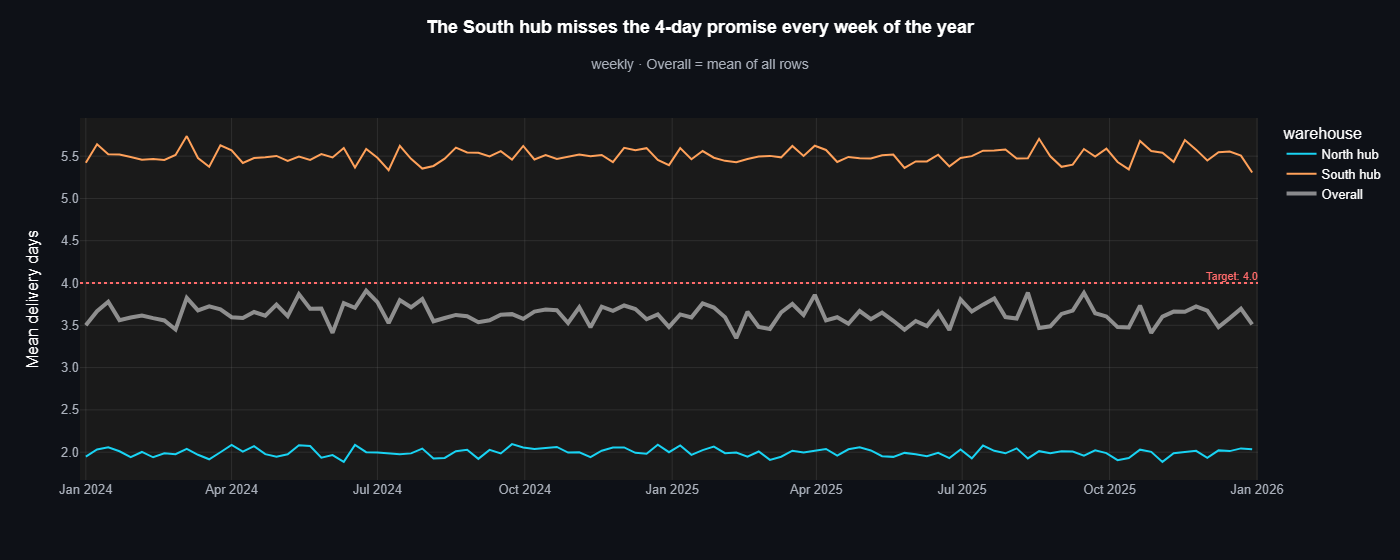

In [41]:
WAREHOUSE_COLORS = {"North hub": "#19D3F3", "South hub": "#FFA15A"}

ev.line_plot(
    orders,
    "order_date",
    "delivery_days",
    color="warehouse",
    agg="mean",
    time_grain="week",
    overall_line=True,
    target=4,
    color_map=WAREHOUSE_COLORS,
    value_format=".1f",
    title="The South hub misses the 4-day promise every week of the year",
    x_title="",
    y_title="Mean delivery days",
)

**How many Gifts orders does a typical week bring?** (*Long-tail product categories*,
pattern 5.) Raw Gifts orders counted per week, the 10 empty weeks drawn as the zeros
they are, and a four-week rolling mean to see the level through the noise.

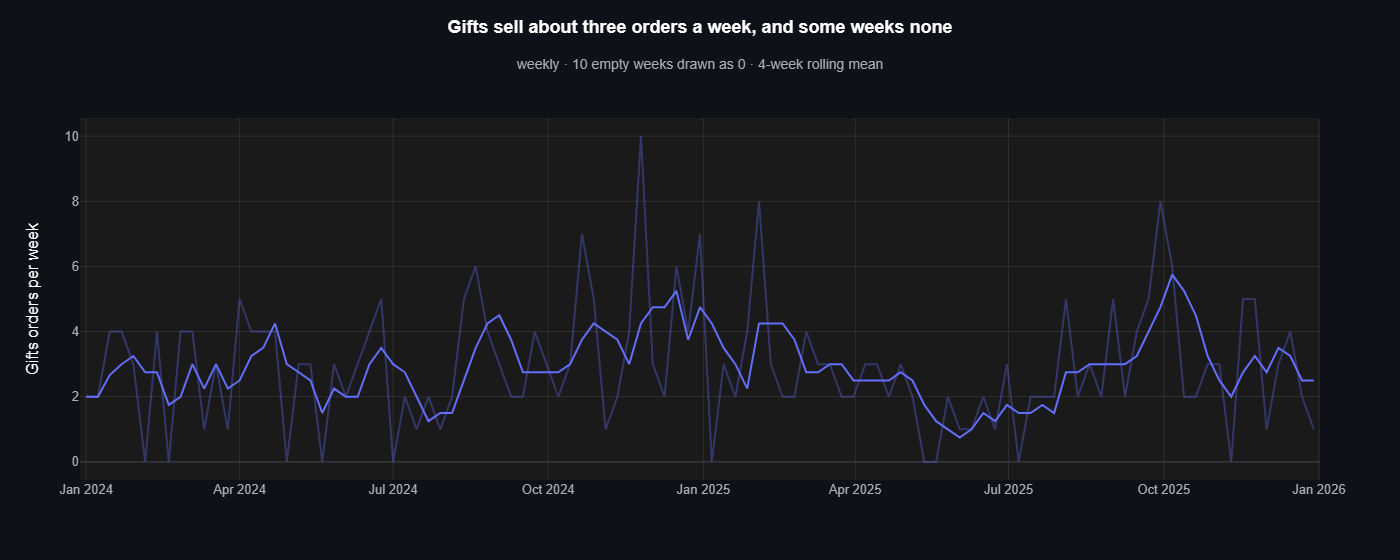

In [42]:
gift_orders = db.sql("""
    SELECT order_date, revenue
    FROM orders JOIN products USING (product_id)
    WHERE category = 'Gifts'
    ORDER BY order_id
""").to_arrow_table()

ev.line_plot(
    gift_orders,
    "order_date",
    agg="count",
    time_grain="week",
    missing_periods="zero",
    rolling=4,
    title="Gifts sell about three orders a week, and some weeks none",
    x_title="",
    y_title="Gifts orders per week",
)

## Limits

`line_plot` refuses an ambiguous request rather than guess, and every message names
the options involved and how to fix it. These are all the option pairs that conflict,
with the error each one gives.

In [43]:
conflicts = {
    "a list y and color": {"y": ["revenue", "profit"], "color": "warehouse"},
    "color the same column as x": {"y": "revenue", "color": "order_date"},
    "no y without a count": {},
    "a band without raw rows": {"y": "revenue", "agg": None, "ci": "bootstrap"},
    "a standard error of a median": {"y": "revenue", "agg": "median", "ci": "sem"},
    "a band and a rolling mean": {
        "y": "revenue",
        "agg": "mean",
        "ci": "bootstrap",
        "rolling": 3,
    },
    "zeros on a log axis": {"y": "revenue", "missing_periods": "zero", "log_y": True},
    "an area on a log axis": {"y": "revenue", "fill_area": True, "log_y": True},
    "a target of 0 on a log axis": {"y": "revenue", "target": 0, "log_y": True},
    "highlight with one line": {"y": "revenue", "highlight": "North hub"},
    "a colour map with one line": {"y": "revenue", "color_map": WAREHOUSE_COLORS},
    "an overall line without color": {"y": "revenue", "overall_line": True},
    "an overall line over a list y": {
        "y": ["revenue", "profit"],
        "overall_line": True,
    },
    "a log x on dates": {"y": "revenue", "log_x": True},
}
for conflict, options in conflicts.items():
    try:
        ev.line_plot(
            orders, "order_date", time_grain="month", **{"agg": "sum", **options}
        )
    except ValueError as error:
        print(f"{conflict}:\n    {error}\n")

a list y and color:
    line_plot: y=['revenue', 'profit'] cannot be combined with color='warehouse'. Pick one shape: a list y for one column per series, or color for series stacked in one column.

color the same column as x:
    line_plot: color='order_date' is the same column as x. color splits the rows into one line per value; to emphasise some x values, use events.

no y without a count:
    line_plot: y is not set. Pass the measure column as y, or use agg='count' to count rows.

a band without raw rows:
    line_plot: ci='bootstrap' needs agg='mean' or agg='median', got agg=None. Pass the raw rows with agg='mean' or 'median', or remove ci.

a standard error of a median:
    line_plot: ci='sem' cannot be combined with agg='median'. The standard error describes a mean: use ci='bootstrap', or agg='mean'.

a band and a rolling mean:
    line_plot: ci='bootstrap' cannot be combined with rolling=3. Remove one of them.

zeros on a log axis:
    line_plot: missing_periods='zero' cannot be

Two more options need a time or numeric axis, and refuse the weekdays: a range slider,
and a calendar grain.

In [44]:
for conflict, options in {
    "a range slider on a text axis": {"rangeslider": True},
    "a calendar grain on a text axis": {"time_grain": "week"},
}.items():
    try:
        ev.line_plot(weekdays, "weekday", "orders", color="year", **options)
    except ValueError as error:
        print(f"{conflict}:\n    {error}\n")

a range slider on a text axis:
    line_plot: rangeslider=True needs a time or numeric x, but x='weekday' is a text column. Remove rangeslider, or pass a date or numeric x.

a calendar grain on a text axis:
    line_plot: time_grain='week' needs a time x, but x='weekday' is a text column. Remove time_grain, or pass a date column as x.



**Rows that repeat an `x` without `agg`.** With `agg=None`, each row is one point, so
an `x` that appears twice is an error, never a silent sum. That also holds after
bucketing: daily rows put on a weekly calendar give seven rows per week.

In [45]:
try:
    ev.line_plot(daily, "date", "orders", time_grain="week")
except ValueError as error:
    print(error)

line_plot: 105 values of x appear in more than one row (e.g. date=2024-01-01 00:00:00), but agg=None plots each row as-is. Set agg (e.g. agg='sum') to combine them, or return one row per x from the query.


**Dates on no calendar.** With `time_grain="auto"`, the dates must sit on a regular
grid. A table sampled on Mondays and Thursdays has none: is it daily with gaps, or
twice a week? `line_plot` asks instead of guessing. `time_grain=None` draws the points
as they are; a grain such as `"week"` would bucket them.

line_plot: time_grain='auto' finds no calendar grain in 'date': its dates fall on day starts, but no two are one day apart (closest: 2024-01-01 and 2024-01-04). Set time_grain to bucket them (e.g. time_grain='week'), or time_grain=None to draw the points as they are.


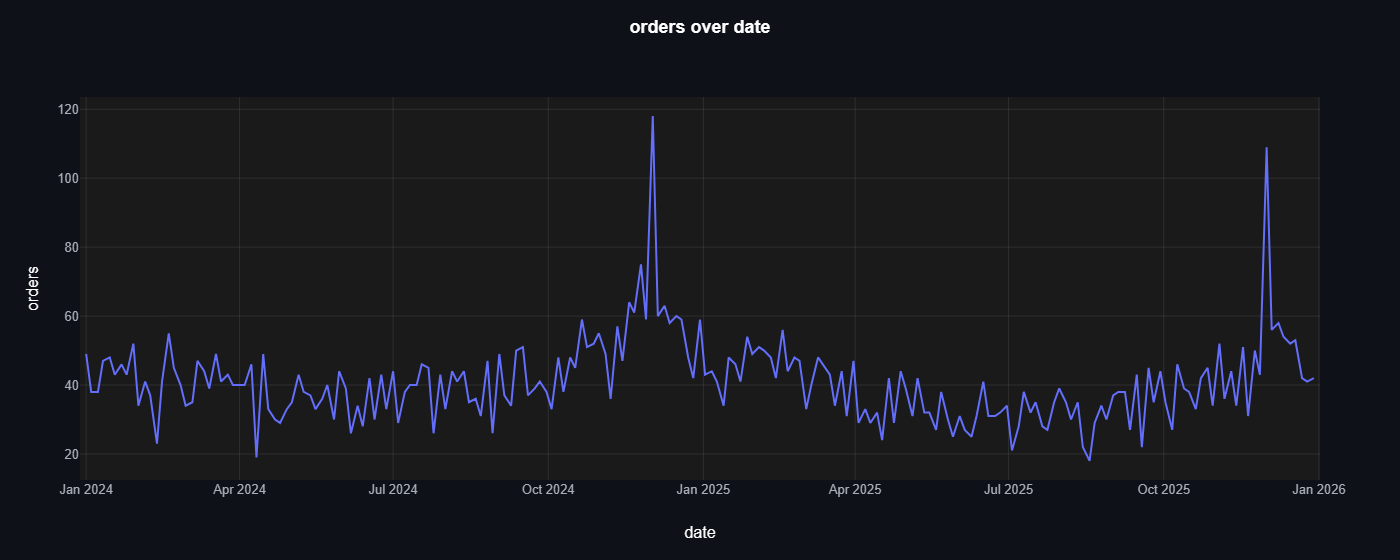

In [46]:
twice_a_week = db.sql("""
    SELECT date, orders
    FROM daily_metrics
    WHERE dayname(date) IN ('Monday', 'Thursday')
    ORDER BY date
""").pl()

try:
    ev.line_plot(twice_a_week, "date", "orders")
except ValueError as error:
    print(error)

ev.line_plot(twice_a_week, "date", "orders", time_grain=None)

**A single date.** One date shows no step, so it gets no calendar: one point, on an
axis that names its date.

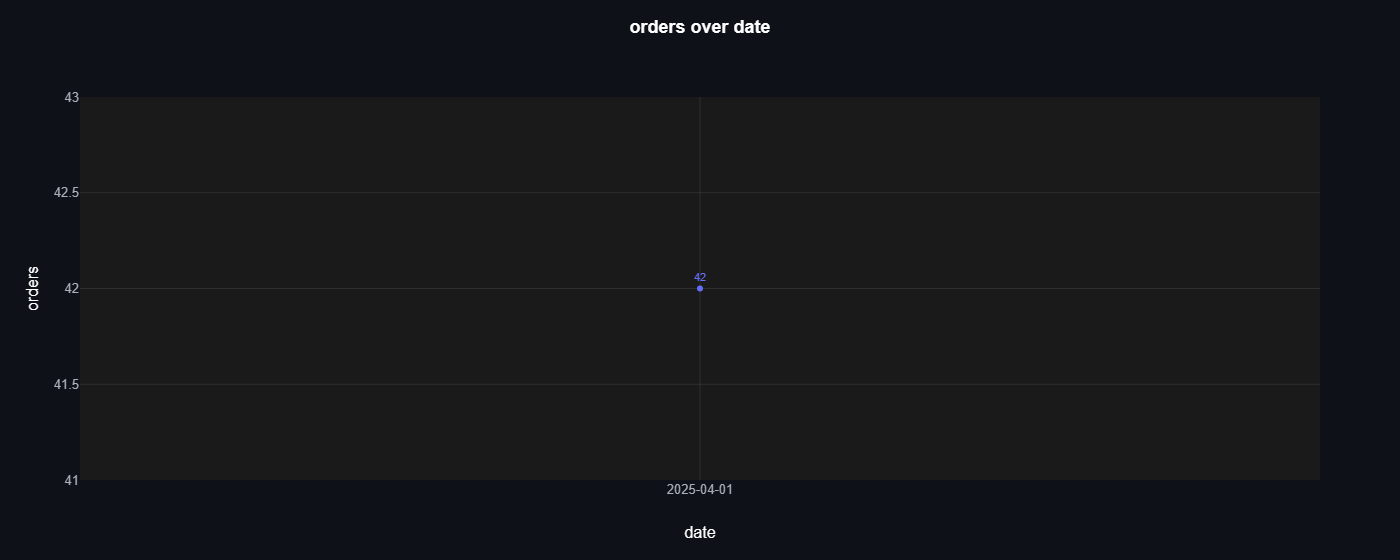

In [47]:
price_day = db.sql("""
    SELECT date, orders
    FROM daily_metrics
    WHERE date = '2025-04-01'
    ORDER BY date
""").pl()

ev.line_plot(price_day, "date", "orders", show_values=True)

**Missing values.** Rows with a missing value in a column the chart uses are dropped,
and a warning says how many. The median income of customers by the year they signed
up drops those who skipped the income question, most of them Students (*Missing not
at random*, pattern 7): a reason to read this line with care.

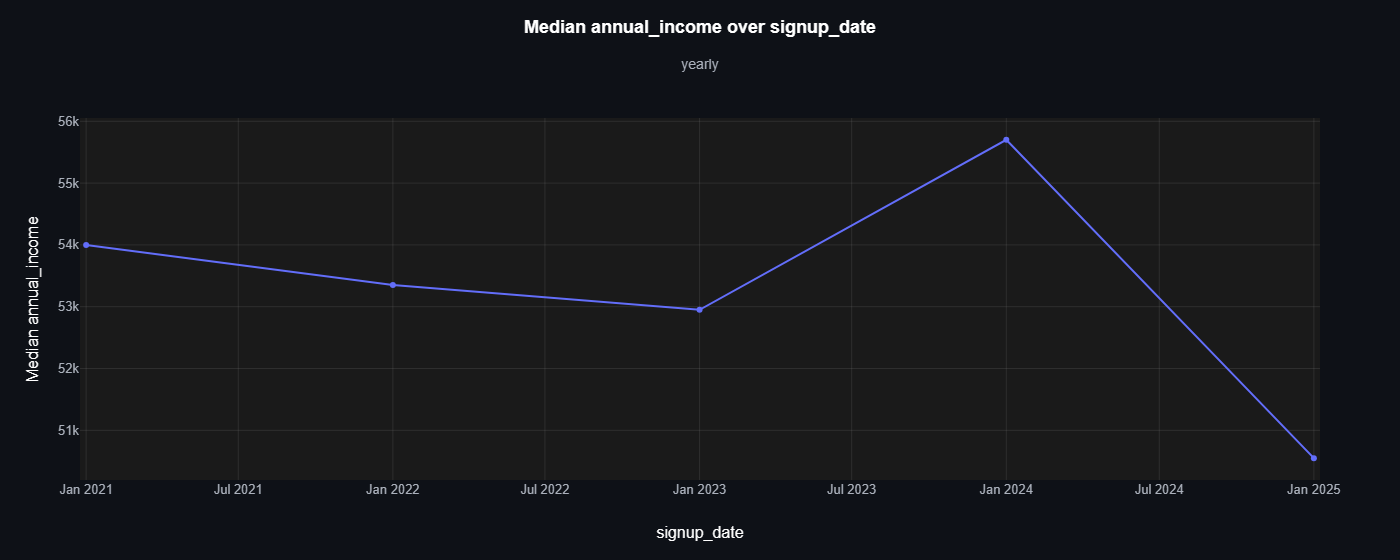

In [48]:
income = db.sql("""
    SELECT signup_date, annual_income
    FROM customers
    ORDER BY customer_id
""").df()

ev.line_plot(income, "signup_date", "annual_income", agg="median", time_grain="year")

**More series than colours.** Eighteen categories need more colours than the theme has
(ten), and lines in recycled colours can't be told apart. The message says what to do:
filter in the query, or highlight the lines that matter, since dimmed lines need no
colour of their own (the `highlight` chart in the tour).

In [49]:
try:
    ev.line_plot(by_category, "month", "revenue", color="category")
except ValueError as error:
    print(error)

line_plot: 18 series need 18 colours, but the theme has 10. Filter the query to fewer series, or highlight the ones that matter (dimmed series need no colour of their own); or pass color_map, or use a theme with a longer colorway.


**An option that does nothing in the current mode warns** instead of being silently
ignored, and is then left out of the chart: here, empty periods without a calendar,
and a one-point rolling mean, which is the value itself.

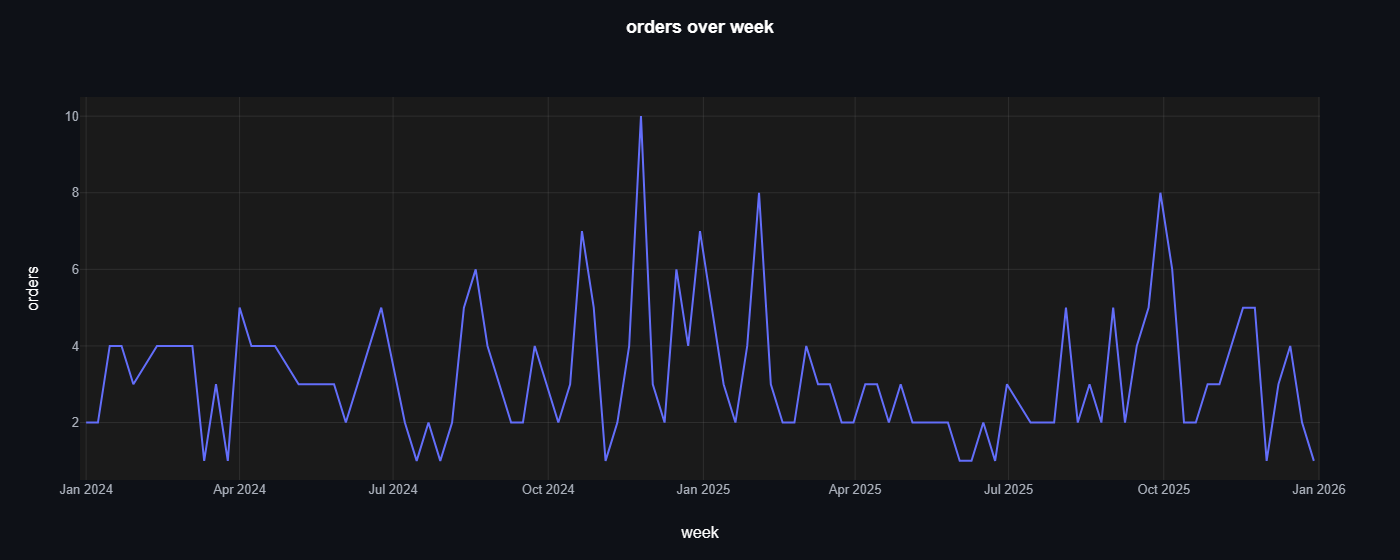

In [50]:
ev.line_plot(
    gifts, "week", "orders", time_grain=None, missing_periods="zero", rolling=1
)

The same holds for hover columns with `agg`: a combined point has no single value for
them, so they are left out, with a warning.

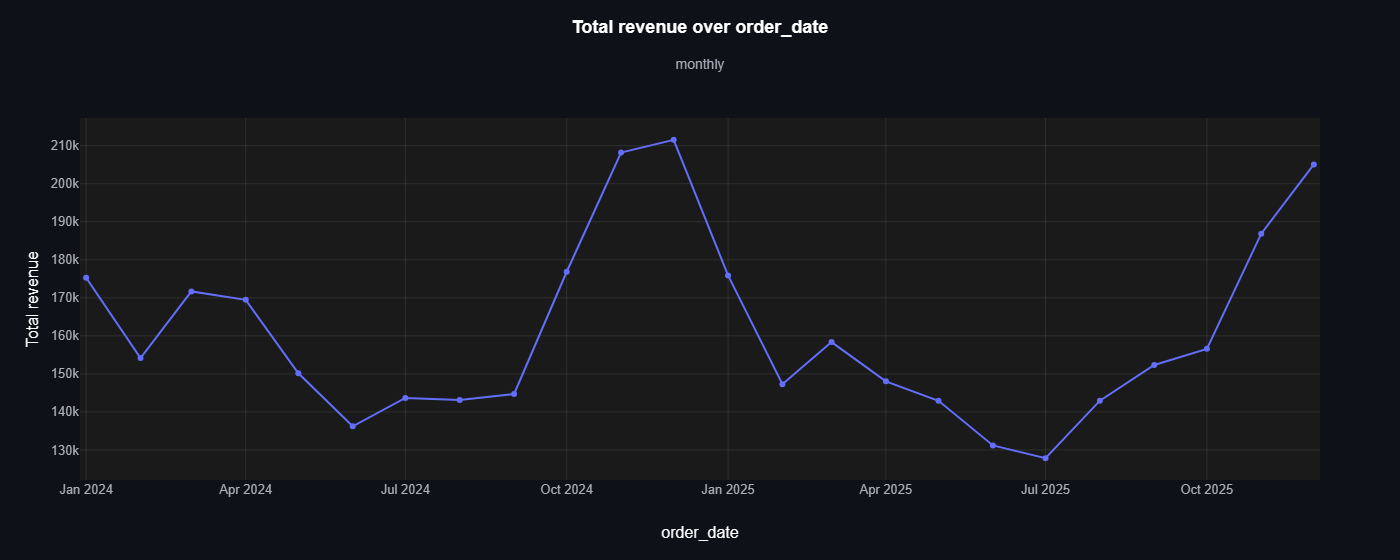

In [51]:
ev.line_plot(
    orders, "order_date", "revenue", agg="sum", time_grain="month", hover="region"
)

**Events outside the data** raise, rather than stretching the axis to a date the data
doesn't reach.

In [52]:
try:
    ev.line_plot(kpis, "month", "conversion_rate", events={"2026-03-01": "Review"})
except ValueError as error:
    print(error)

line_plot: events has the key '2026-03-01', outside the x range (2024-01-01 to 2025-12-01). Use x values within the data, or filter the events.


**A band that reaches 0 on a log axis.** A week with two or three Gifts orders has a
mean but a wide interval, and its lower end can fall to 0 or below, where a log axis
has no room. Cutting the band at the axis floor would misstate the interval, so the
call raises and counts the band ends that can't be drawn.

In [53]:
try:
    ev.line_plot(
        gift_orders,
        "order_date",
        "revenue",
        agg="mean",
        time_grain="week",
        ci="sem",
        log_y=True,
    )
except ValueError as error:
    print(error)

line_plot: log_y=True cannot draw 7 confidence-band ends at or below 0 (ci='sem'): a log axis has no 0 or negative values. Remove log_y to see the whole band, or remove ci.


## Insight story

**What did the 12 % price rise on 1 April 2025 do?** (*Seasonality and a structural
break after a price rise*, pattern 4.) Finance wants to know whether the rise paid off.
Start where the bare call left off: daily orders, a zigzag of weekdays, seasons and
promotions in which no change of level can be seen.

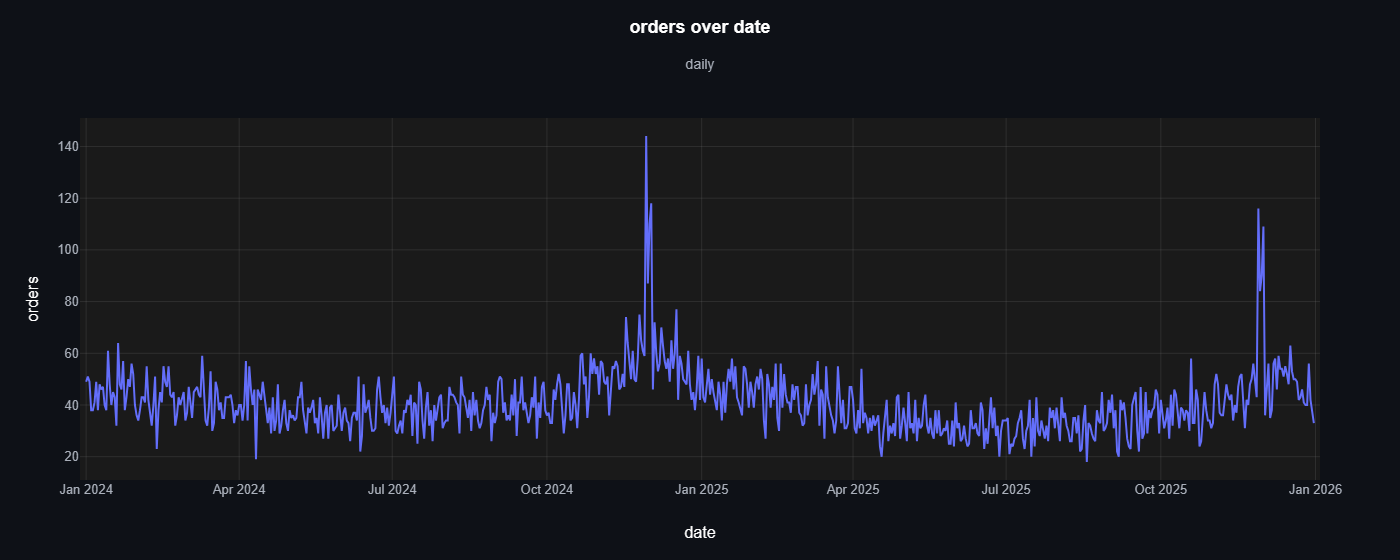

In [54]:
ev.line_plot(daily, "date", "orders")

A 7-day rolling mean averages each full week, so the weekday cycle disappears. What
is left is the yearly wave, low in early summer and high in November and December, and
the two Black Friday spikes, each about 2.7 times the four weeks before.

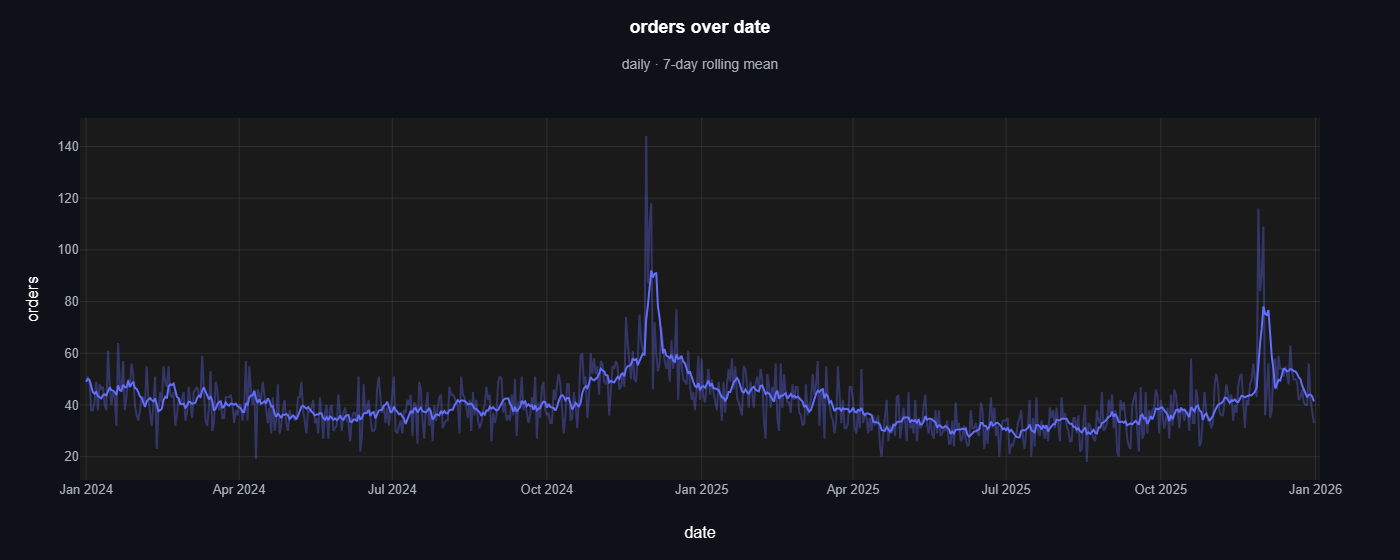

In [55]:
ev.line_plot(daily, "date", "orders", rolling=7)

A 28-day window smooths the spikes too, and an event line marks the price rise. The
line dips into every summer, so compare the months after the rise with the same months
of 2024, which cancels the season: April to October 2025 averaged 33.1 orders a day
against 39.0 a year earlier, 15 % fewer, while January to March had been level with
2024. The trailing window takes four weeks to settle at the new level.

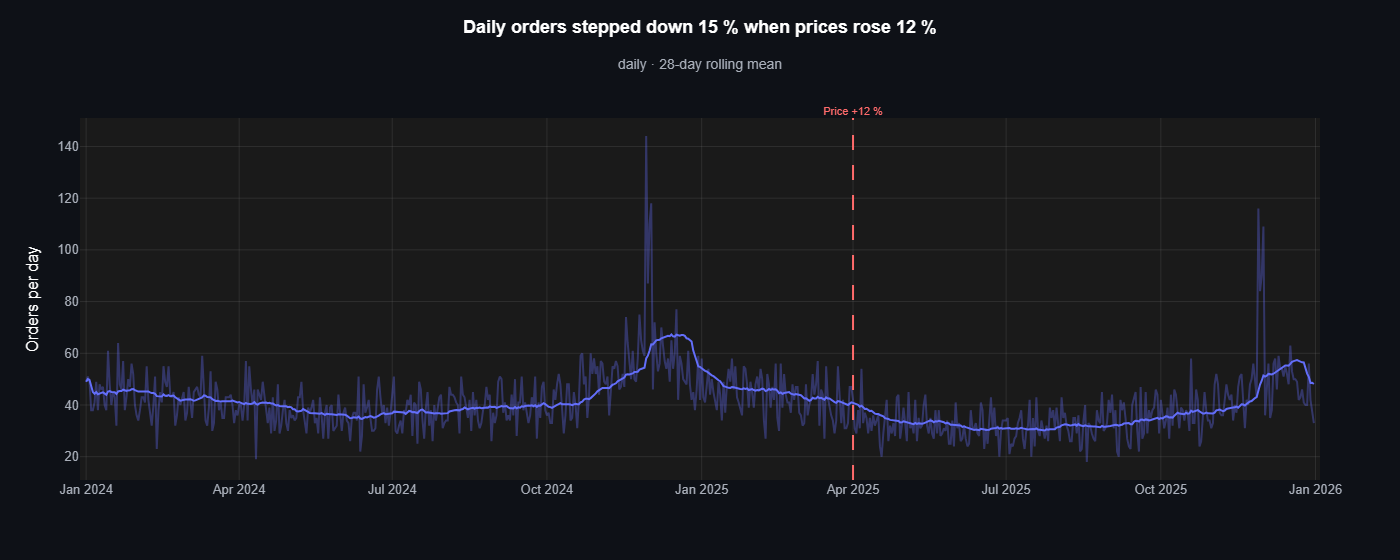

In [56]:
ev.line_plot(
    daily,
    "date",
    "orders",
    rolling=28,
    events={"2025-04-01": "Price +12 %"},
    title="Daily orders stepped down 15 % when prices rose 12 %",
    x_title="",
    y_title="Orders per day",
)

Traffic did not fall: the `rolling` chart in the tour shows site sessions at the same
level in both years. So fewer visitors buy, and the conversion rate steps down at the
event line, from 2.80 % to 2.37 % comparing April to October of each year.

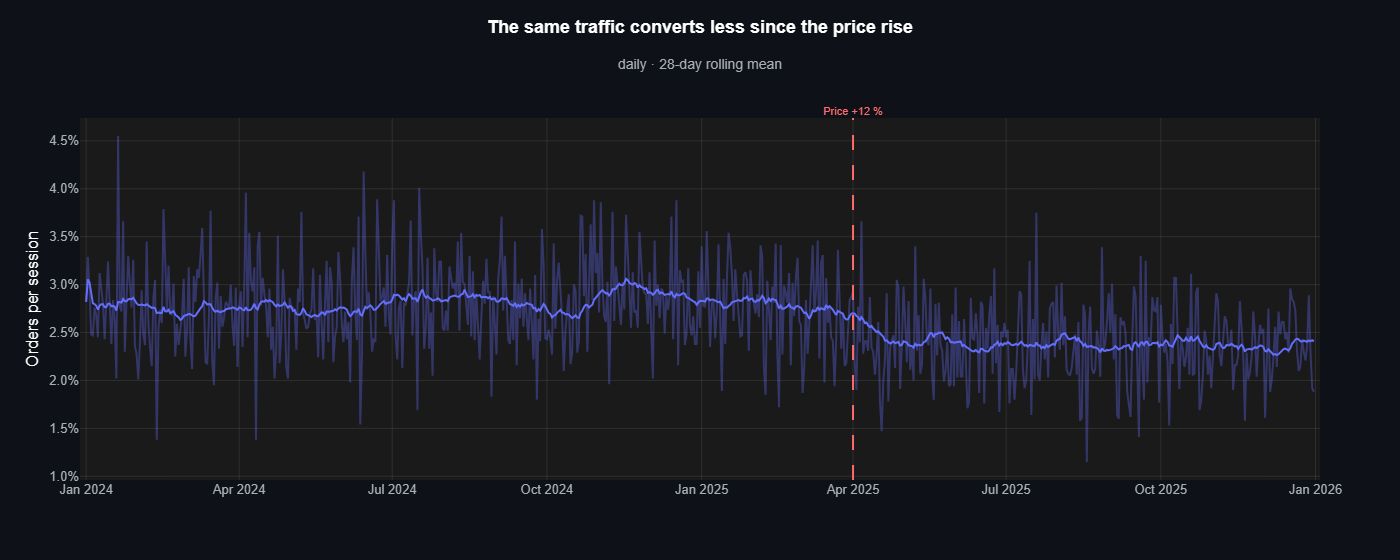

In [57]:
ev.line_plot(
    daily,
    "date",
    "conversion_rate",
    rolling=28,
    events={"2025-04-01": "Price +12 %"},
    value_format=".1%",
    title="The same traffic converts less since the price rise",
    x_title="",
    y_title="Orders per session",
)

And each order is worth more: over the same months the average order value rose about
11 %, from 127.64 to 141.31 dollars.

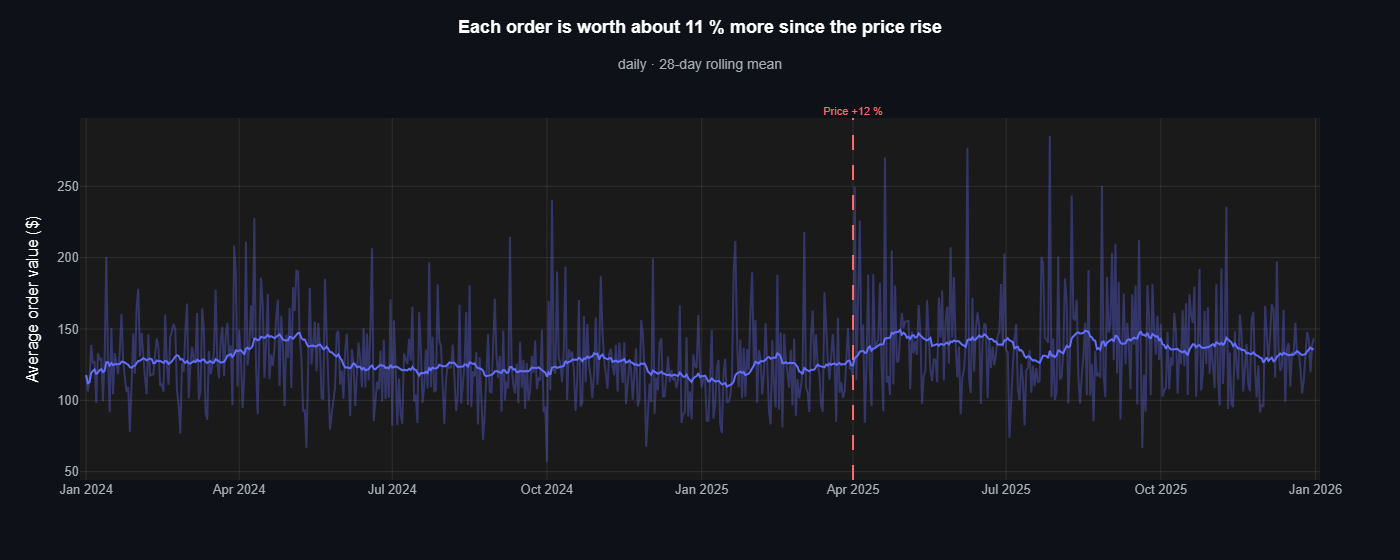

In [58]:
ev.line_plot(
    daily,
    "date",
    "avg_order_value",
    rolling=28,
    events={"2025-04-01": "Price +12 %"},
    title="Each order is worth about 11 % more since the price rise",
    x_title="",
    y_title="Average order value ($)",
)

**Finding:** the price rise traded volume for value. 15 % fewer orders at 11 % more per
order leave revenue about 6 % lower than a year earlier (0.85 × 1.11 ≈ 0.94), on the
same traffic. Whether that pays depends on the margins, but the charts say plainly
where the business was lost: at checkout, not in visitors.

## Escape hatch

The result is a plain Plotly figure, and every trace carries a role (`data` for the
lines, `trendline` for rolling means, `ci` for bands, `reference` for the overall,
average, target and event lines). A slide might want the rolling mean heavier than the
default; select it by its role and change it with Plotly.

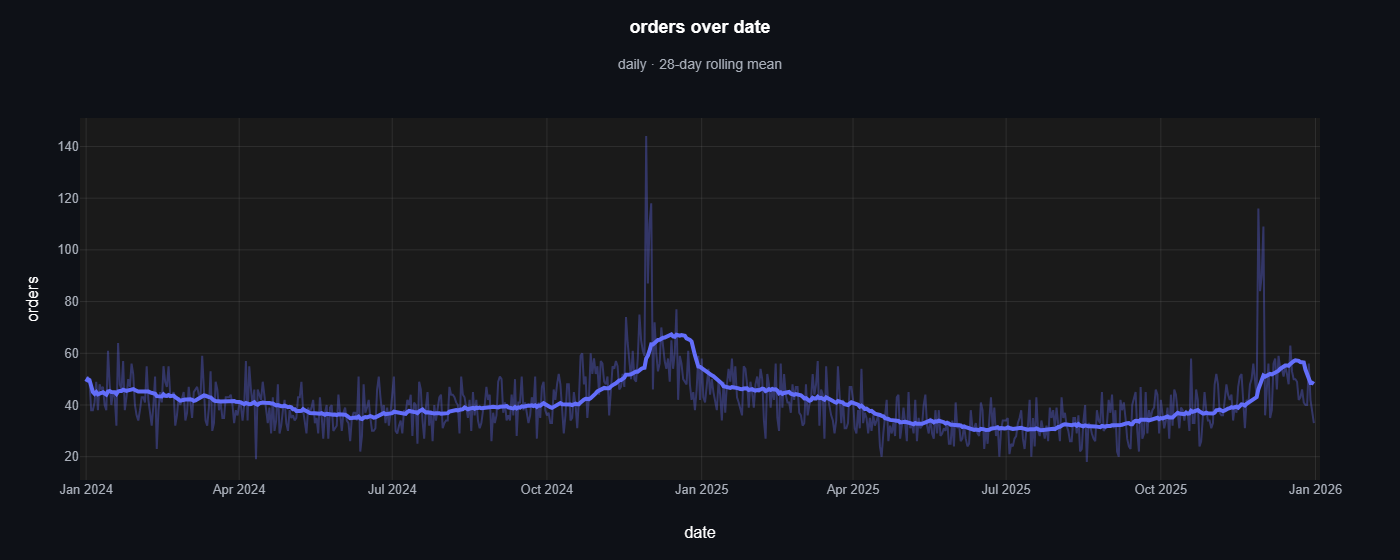

In [59]:
fig = ev.line_plot(daily, "date", "orders", rolling=28)
fig.update_traces(
    line_width=4,
    selector=lambda trace: (trace.meta or {}).get("role") == "trendline",
)